# **Introduction**

## Dataset Description & Source

The dataset used in this project is the **Mobile Phones Specifications and Prices** dataset, publicly available on **Kaggle** (https://www.kaggle.com/datasets/kiiroisenkoxx/2025-mobile-phones-in-indian-market-datasets). 
It contains **7,166 mobile phone records** collected from a variety of mobile phones in the Indian market as of 2025, covering devices released by over 30 global manufacturers.

**Source:** Kaggle — [2025] Mobile Phones in Indian Market Datasets  
**Domain:** Consumer Electronics / Technology Market  
**Instances:** 7,166  
**Features:** 26 (mix of numeric and categorical)

The dataset contains **26 features**, a rich mix of:
- **Numeric attributes (16):** `cpu_cores`, `cpu_speed`, `ram`, `storage`, `battery`, `screen_size`, `refresh_rate`, `ppi`,  `rear_cameras`, `rear_primary`, `front_cameras`, `front_primary`, `spec_score`, `user_rating`, `price`, `expandable_upto`
- **Categorical attributes (7):** `name`, `brand`, `os`, `cpu_brand`, `cpu_name`, `aspect_ratio_category`, `screen_res`
- **Binary flags (3):** `5g`, `nfc`, `ir_blaster`  

These features can be classified into categories:
| Category | Features |
|---|---|
| Device Identity | `name`, `brand`, `os` |
| Processor | `cpu_brand`, `cpu_name`, `cpu_cores`, `cpu_speed` |
| Connectivity | `5g`, `nfc`, `ir_blaster` |
| Hardware | `ram`, `storage`, `battery`, `expandable_upto` |
| Display | `screen_size`, `aspect_ratio_category`, `screen_res`, `refresh_rate`, `ppi` |
| Camera | `rear_cameras`, `rear_primary`, `front_cameras`, `front_primary` |
| Market Metrics | `spec_score`, `user_rating`, `price` |

## Domain Motivation

The global smartphone market generates over **$500 billion in annual revenue**, with thousands of new devices released every year. Consumers, retailers, and manufacturers all face the challenge of navigating an extraordinarily complex product landscape where devices vary across dozens of technical dimensions and price points ranging from entry-level to ultra-premium.

**This project applies data mining to answer three key questions:**

1. **How do mobile phones naturally cluster?** K-Medoids and Hierarchical Clustering reveal natural market segments based on hardware specifications and pricing, without relying on manufacturer-defined tiers.

2. **How can we recommend a purchase decision intelligently?** A Fuzzy Logic System translates numeric specs and pricing into a human-interpretable recommendation score, incorporating the cluster tier as contextual evidence.

3. **Which features matter most for segmentation?** A Genetic Algorithm searches the feature space to identify the optimal subset that maximises clustering quality, removing noise and reducing dimensionality.

**Business value:** Understanding how devices cluster by hardware capability and price can provide strategic insights for:
- **Manufacturers**: Identify gaps in the market and optimize product lines.
- **Retailers**: Build segmentation-based marketing campaigns.
- **Consumers**: Navigate the overwhelming number of choices.

# Library Imports

In [1]:
!pip install -q scikit-learn-extra --upgrade
!pip install pandas==2.2.2
!pip install numpy==1.26.4
!pip install -q scikit-fuzzy --upgrade

In [138]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import warnings
warnings.filterwarnings('ignore')

# **Exploratory Data Analysis (EDA)**
In this step we only inspect the data to know what are the problems that we need to solve and to get a better understanding of the features' nature. We will then use our observations to perform necessary preprocessing on the data.

In [139]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [140]:
df = pd.read_csv('/content/drive/MyDrive/mobiles.csv')

In [141]:
df.shape

(7166, 26)

In [142]:
df.head()

,name,brand,os,cpu_brand,cpu_name,cpu_cores,cpu_speed,5g,nfc,ir_blaster,...,refresh_rate,ppi,rear_cameras,rear_primary,front_cameras,front_primary,expandable_upto,spec_score,user_rating,price
0,samsung galaxy s24 fe 5g,samsung,android,exynos,exynos 2400e,10.0,3.11,1,1,0,...,120,384.66,3,50.0,1,10.0,0.0,84,4.00,34999.0
1,samsung galaxy s24 ultra,samsung,android,snapdragon,snapdragon 8 gen3,8.0,3.30,1,1,0,...,120,505.33,1,200.0,1,12.0,0.0,92,4.35,84949.0
2,samsung galaxy s25 edge,samsung,android,snapdragon,snapdragon 8elite,8.0,4.47,1,1,0,...,120,512.88,2,200.0,1,12.0,0.0,89,4.45,109999.0
3,samsung galaxy m36 5g,samsung,android,exynos,exynos 1380,8.0,2.40,1,1,0,...,120,382.38,3,50.0,1,16.0,1024.0,82,4.55,19990.0
4,samsung galaxy m06 5g,samsung,android,mediatek,dimensity 6300,8.0,2.40,1,0,0,...,90,260.32,2,50.0,1,8.0,1536.0,72,4.00,7999.0


In [143]:
df.tail()

,name,brand,os,cpu_brand,cpu_name,cpu_cores,cpu_speed,5g,nfc,ir_blaster,...,refresh_rate,ppi,rear_cameras,rear_primary,front_cameras,front_primary,expandable_upto,spec_score,user_rating,price
7161,meizu m2 note,meizu,android,helio,helio mt6753,8.0,1.3,0,0,0,...,60,400.53,1,13.0,1,5.0,128.0,53,4.30,4999.0
7162,meizu mx5,meizu,android,helio,helio mt6795,8.0,2.2,0,0,0,...,60,400.53,1,20.7,1,5.0,0.0,58,4.15,14990.0
7163,meizu m1 note,meizu,android,helio,helio mt6752,8.0,1.7,0,0,0,...,60,400.53,1,13.0,1,5.0,0.0,53,3.90,14499.0
7164,meizu mx4,meizu,android,other,a17,8.0,2.2,0,0,0,...,60,417.74,1,20.7,1,2.0,0.0,60,4.35,23999.0
7165,meizu mx4 pro,meizu,android,exynos,exynos 5430,8.0,2.0,0,1,0,...,60,542.81,1,20.7,1,5.0,0.0,62,3.90,21990.0


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7166 entries, 0 to 7165
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   name                   7166 non-null   object 
 1   brand                  7166 non-null   object 
 2   os                     7166 non-null   object 
 3   cpu_brand              6151 non-null   object 
 4   cpu_name               6366 non-null   object 
 5   cpu_cores              7109 non-null   float64
 6   cpu_speed              6801 non-null   float64
 7   5g                     7166 non-null   int64  
 8   nfc                    7166 non-null   int64  
 9   ir_blaster             7166 non-null   int64  
 10  ram                    7126 non-null   float64
 11  storage                7156 non-null   float64
 12  battery                7125 non-null   float64
 13  screen_size            7162 non-null   float64
 14  aspect_ratio_category  7144 non-null   object 
 15  scre

In [145]:
for col in df.columns:
    print(f"Column {col}:")
    print(f"Number of unique values: {len(df[col].value_counts())}")
    print(f"Number of null values: {df[col].isnull().sum()}")
    print("------------------------------")

Column name:
Number of unique values: 7166
Number of null values: 0
------------------------------
Column brand:
Number of unique values: 47
Number of null values: 0
------------------------------
Column os:
Number of unique values: 4
Number of null values: 0
------------------------------
Column cpu_brand:
Number of unique values: 12
Number of null values: 1015
------------------------------
Column cpu_name:
Number of unique values: 833
Number of null values: 800
------------------------------
Column cpu_cores:
Number of unique values: 8
Number of null values: 57
------------------------------
Column cpu_speed:
Number of unique values: 80
Number of null values: 365
------------------------------
Column 5g:
Number of unique values: 2
Number of null values: 0
------------------------------
Column nfc:
Number of unique values: 2
Number of null values: 0
------------------------------
Column ir_blaster:
Number of unique values: 2
Number of null values: 0
------------------------------
Col

Columns such as `cpu_brand`, `cpu_name`, `cpu_cores`, `cpu_speed`, `ram`, `storage`, `battery`, `screen_size`, `aspect_ratio_category`,  `screen_res`, `ppi`, `rear_primary` and `front_primary` have a few null values which need to be handeled.

Notice that `5g`, `nfc` and `ir_blaster` columns have only **2** unique values which means they are binary.

In [146]:
duplicates = df.duplicated().sum()
print(f"Number of duplicates: {duplicates}")

Number of duplicates: 0


### Column `name` is just a unique identifier, so we use it as index

In [147]:
df.set_index('name', inplace=True)

In [148]:
df.shape

(7166, 25)

### Identifying the type of the features

In [149]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
object_features = df.select_dtypes(include=['object']).columns.tolist()

In [150]:
numerical_features

['cpu_cores',
 'cpu_speed',
 '5g',
 'nfc',
 'ir_blaster',
 'ram',
 'storage',
 'battery',
 'screen_size',
 'refresh_rate',
 'ppi',
 'rear_cameras',
 'rear_primary',
 'front_cameras',
 'front_primary',
 'expandable_upto',
 'spec_score',
 'user_rating',
 'price']

In [151]:
object_features

['brand', 'os', 'cpu_brand', 'cpu_name', 'aspect_ratio_category', 'screen_res']

### Taking a close look on the numerical features

In [152]:
df[numerical_features].describe()

,cpu_cores,cpu_speed,5g,nfc,ir_blaster,ram,storage,battery,screen_size,refresh_rate,ppi,rear_cameras,rear_primary,front_cameras,front_primary,expandable_upto,spec_score,user_rating,price
count,7109.000000,6801.000000,7166.000000,7166.000000,7166.000000,7126.000000,7156.000000,7125.000000,7162.000000,7166.000000,7141.000000,7166.000000,7165.000000,7166.000000,7117.000000,7166.000000,7166.000000,7166.000000,7166.000000
mean,7.270221,2.195823,0.384733,0.383059,0.133268,5.750631,126.398189,4369.791298,6.257971,82.378872,361.306768,1.899246,37.652980,1.032236,14.688305,270.976411,70.042423,4.312106,25183.024653
std,1.559453,0.615233,0.486566,0.486166,0.339888,3.355736,123.011271,1277.270851,0.619518,29.176892,81.456738,0.848566,31.221225,0.208525,11.547953,448.290628,13.156522,0.297311,26665.230162
min,1.000000,0.002000,0.000000,0.000000,0.000000,1.000000,1.170000,2000.000000,5.000000,60.000000,48.790000,0.000000,0.000000,0.000000,0.300000,0.000000,10.000000,1.250000,3537.000000
25%,8.000000,1.800000,0.000000,0.000000,0.000000,3.000000,32.000000,3450.000000,5.990000,60.000000,270.400000,1.000000,13.000000,1.000000,8.000000,0.000000,60.000000,4.150000,9364.500000
50%,8.000000,2.200000,0.000000,0.000000,0.000000,6.000000,128.000000,4500.000000,6.500000,60.000000,394.510000,2.000000,48.000000,1.000000,12.000000,32.000000,73.000000,4.350000,16498.500000
75%,8.000000,2.500000,1.000000,1.000000,0.000000,8.000000,128.000000,5000.000000,6.670000,120.000000,404.890000,3.000000,50.000000,1.000000,16.000000,256.000000,81.000000,4.550000,29990.000000
max,10.000000,4.470000,1.000000,1.000000,1.000000,24.000000,1024.000000,25500.000000,11.500000,185.000000,801.060000,3.000000,200.000000,2.000000,60.000000,2048.000000,98.000000,5.000000,480000.000000


Notice the min value of the `5g`, `nfc` and `ir_blaster` columns is **0** which means the mobile doesn't have it, and max is **1** which means it has it.

### Detecting Outliers

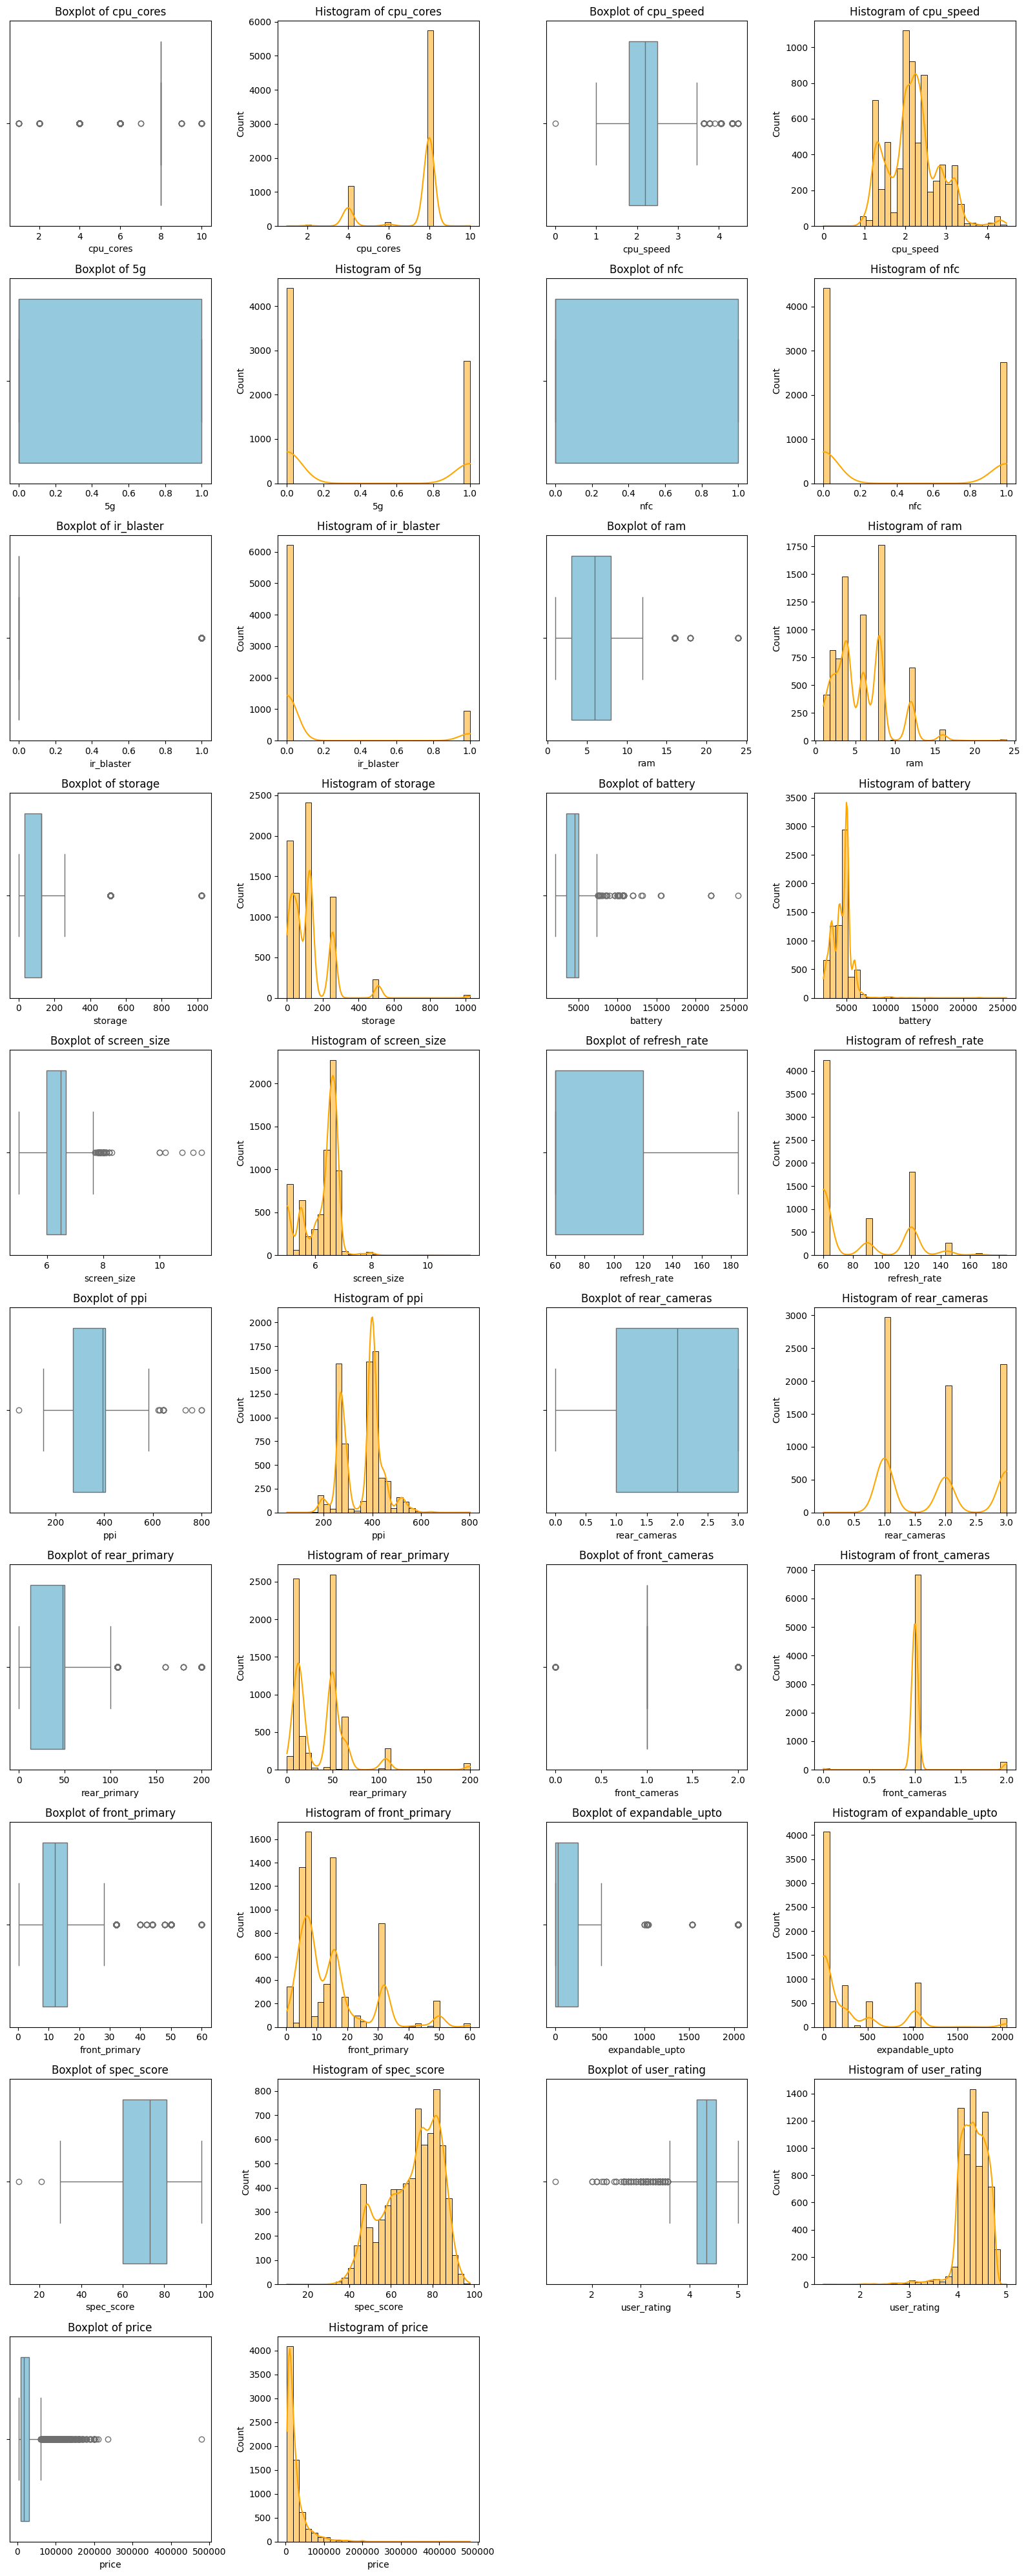

In [153]:
import math
n_features = len(numerical_features)
n_rows = math.ceil(n_features / 2)

fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4 * n_rows))
axes = axes.reshape(-1)

for i, col in enumerate(numerical_features):
    ax_box = axes[i * 2]
    ax_hist = axes[i * 2 + 1]
    # Boxplot
    sns.boxplot(x=df[col], ax=ax_box, color='skyblue')
    ax_box.set_title(f'Boxplot of {col}')
    # Histogram
    sns.histplot(df[col], bins=30, ax=ax_hist, kde=True, color='orange')
    ax_hist.set_title(f'Histogram of {col}')

for j in range(2 * n_features, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

These outliers need to be handled differently as they represent different meanings.
- **Keep as-is**: `cpu_cores`, `ram`, `refresh_rate`, `rear_cameras`, `front_cameras`, `user_rating`, `expandable_upto`
- **Winsorize / cap**: `cpu_speed`, `screen_size`, `front_primary`
- **IQR / Z-score removal**: `battery`, `ppi`, `spec_score`
- **Log transform**: `storage`, `rear_primary`, `price`

**Keep as-is**: used when values are discrete tiers or bounded by design. Removing them would delete real products. \
**Winsorize / cap**: used when a column has a ceiling but a few values exceed it. Capping at the 99th percentile retains all rows while limiting the influence of extremes. \
**IQR / Z-score removal**: used when the distribution is roughly normal and stray values are likely data errors. \
**Log transform**: used when a column spans orders of magnitude. This compresses the tail mathematically rather than removing data.

# **Visualizations**

The following five visualizations cover feature distributions, feature correlations, and categorical breakdowns. Each plot is followed by a written interpretation of what it reveals about the dataset.

### Visualization 1 — Price Distribution

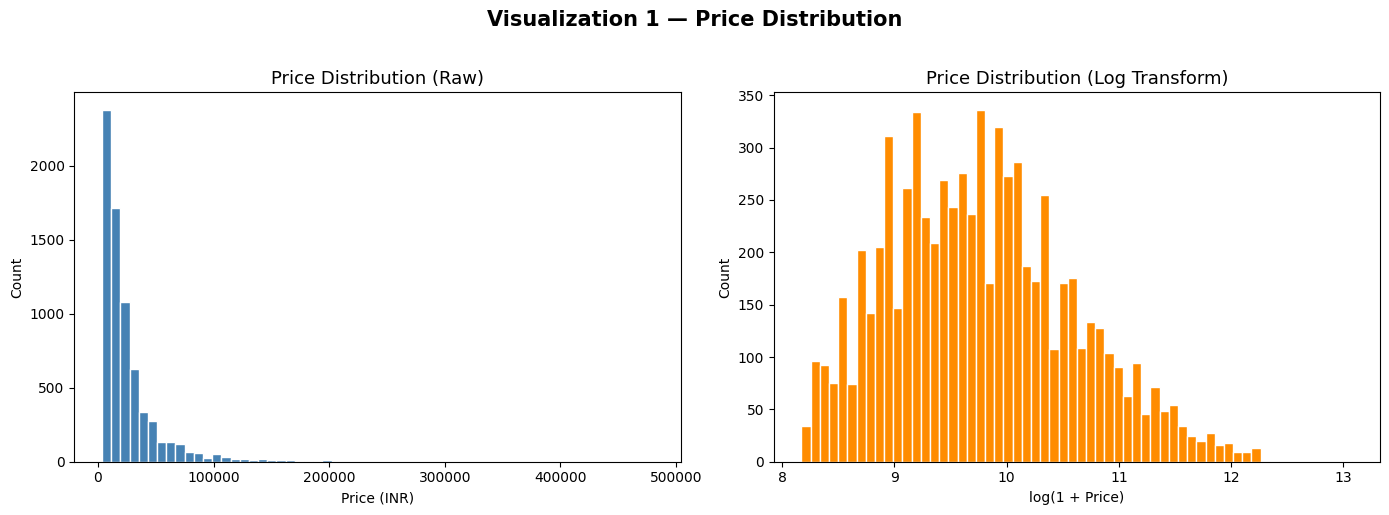

In [154]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw price
axes[0].hist(df['price'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Price Distribution (Raw)', fontsize=13)
axes[0].set_xlabel('Price (INR)')
axes[0].set_ylabel('Count')

# Log-transformed price
axes[1].hist(np.log1p(df['price']), bins=60, color='darkorange', edgecolor='white')
axes[1].set_title('Price Distribution (Log Transform)', fontsize=13)
axes[1].set_xlabel('log(1 + Price)')
axes[1].set_ylabel('Count')

plt.suptitle('Visualization 1 — Price Distribution', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretation:** The raw price distribution is extremely right-skewed, with the vast majority of devices priced below ₹30,000 and a long tail extending to ultra-premium devices. This confirms a highly unequal market where the bulk of offerings are budget-to-mid-range devices. The log-transformed distribution reveals an approximately bell-shaped curve centered around log(price) ≈ 10 (roughly ₹22,000), exposing three loosely visible humps that correspond to budget, mid-range, and premium market tiers. This skewness is why a log transformation is the correct outlier treatment for `price` before clustering or modelling.

### Visualization 2 — RAM vs. Price Coloured by 5G Support

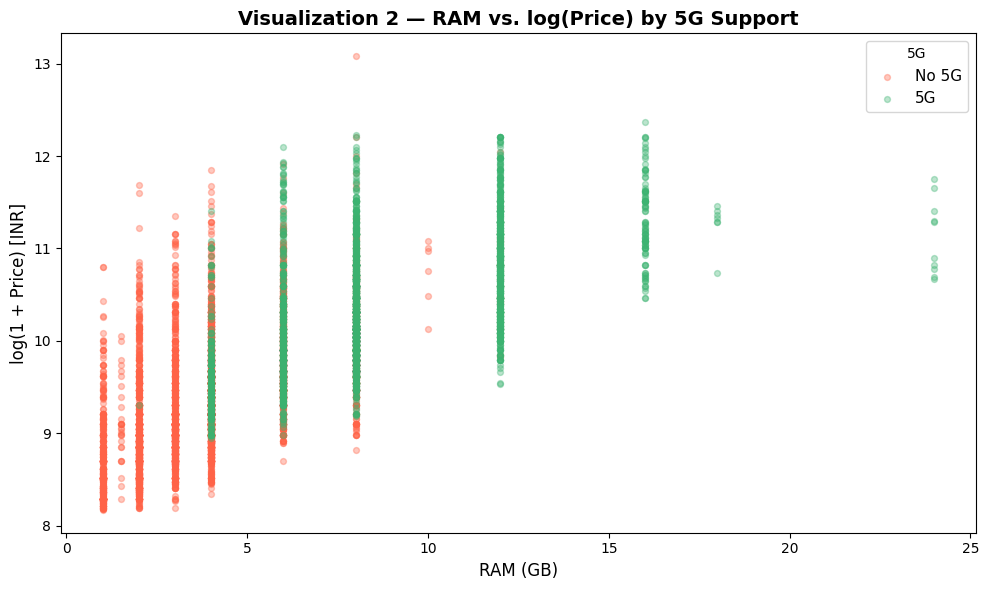

In [155]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = {0: 'tomato', 1: 'mediumseagreen'}
labels = {0: 'No 5G', 1: '5G'}

for val in [0, 1]:
    subset = df[df['5g'] == val]
    ax.scatter(subset['ram'], np.log1p(subset['price']), alpha=0.35, s=18, color=colors[val], label=labels[val])

ax.set_xlabel('RAM (GB)', fontsize=12)
ax.set_ylabel('log(1 + Price) [INR]', fontsize=12)
ax.set_title('Visualization 2 — RAM vs. log(Price) by 5G Support', fontsize=14, fontweight='bold')
ax.legend(title='5G', fontsize=11)
plt.tight_layout()
plt.show()

**Interpretation:** There is a clear positive relationship between RAM and price; devices with higher RAM are consistently more expensive. More importantly, 5G devices (green) form a distinct band at higher price points for any given RAM tier, while non-5G devices (red) dominate the lower price spectrum. This tells us that 5G connectivity is a meaningful market differentiator: it adds price premium beyond hardware specs alone. The overlap in the 4–8 GB RAM range suggests that the mid-market is where manufacturers compete on connectivity rather than raw memory, making 5G a useful feature for cluster separation.

### Visualization 3 — Correlation Heatmap of Numerical Features

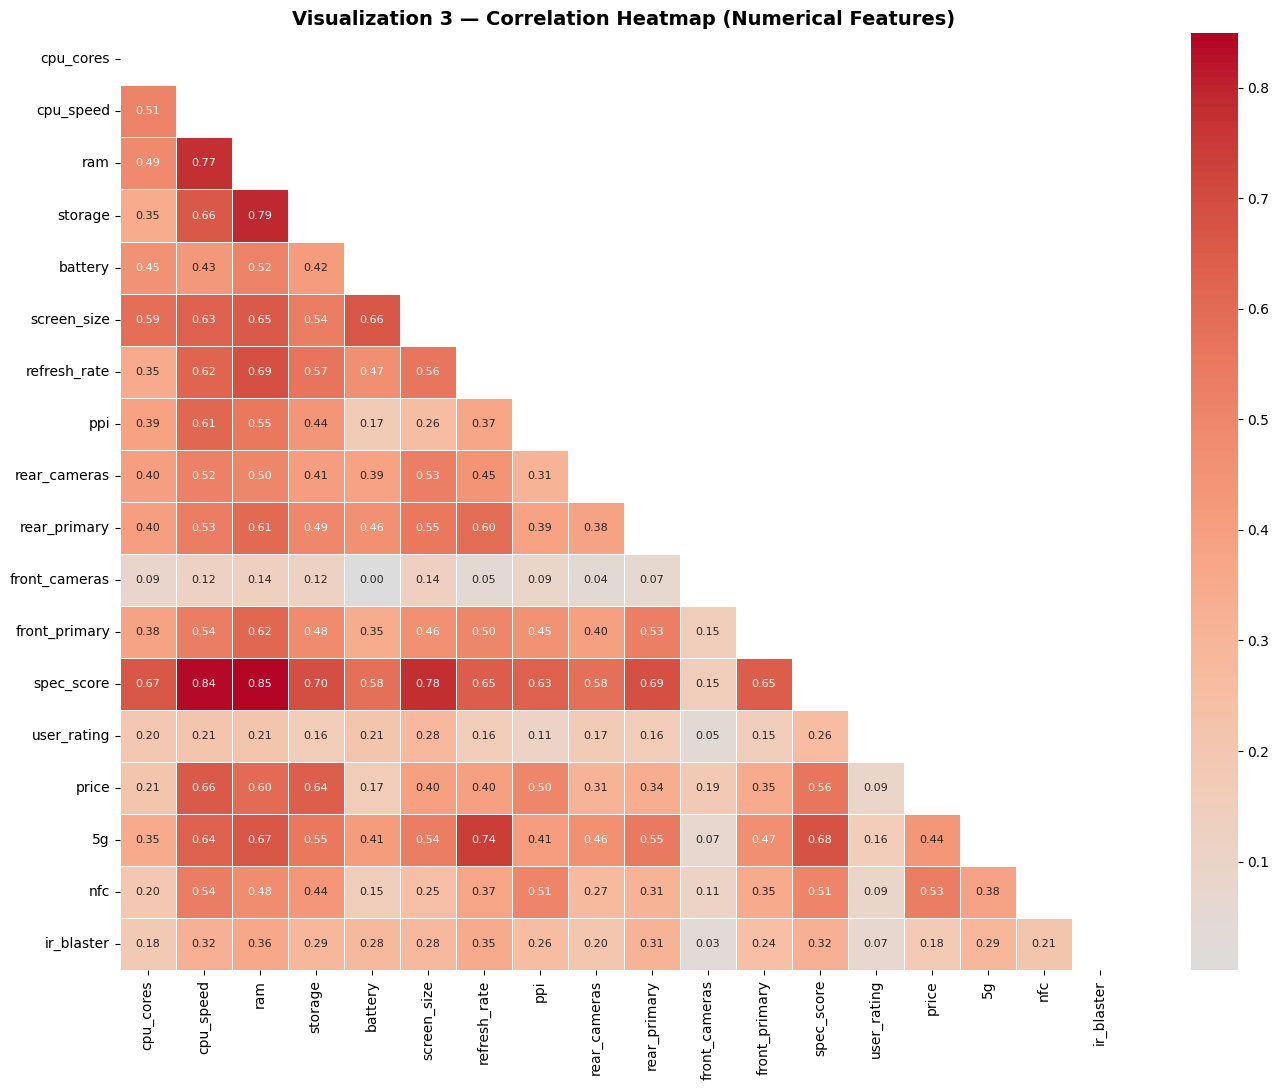

In [156]:
fig, ax = plt.subplots(figsize=(14, 11))

numeric_cols = ['cpu_cores', 'cpu_speed', 'ram', 'storage', 'battery',
                'screen_size', 'refresh_rate', 'ppi', 'rear_cameras',
                'rear_primary', 'front_cameras', 'front_primary',
                'spec_score', 'user_rating', 'price', '5g', 'nfc', 'ir_blaster']

corr = df[numeric_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.4, ax=ax, annot_kws={'size': 8})

ax.set_title('Visualization 3 — Correlation Heatmap (Numerical Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** Several notable correlations emerge:

**Strongest hardware relationships:**
- `spec_score` ↔ `ram` (0.85) and `spec_score` ↔ `cpu_speed` (0.84) are the two strongest correlations in the entire matrix, confirming that spec_score is essentially a weighted summary of processor and memory capability. Using all three together in clustering would introduce significant redundancy.
- `ram` ↔ `storage` (0.79) and `ram` ↔ `cpu_speed` (0.77) show that manufacturers bundle high RAM with high storage and fast CPUs; devices are rarely "unbalanced" across these dimensions.

**Display and connectivity cluster:**
- `refresh_rate` ↔ `5g` (0.74) is surprisingly high for two seemingly unrelated features, revealing that high-refresh-rate displays are a premium feature consistently co-bundled with 5G connectivity rather than offered independently.
- `battery` ↔ `screen_size` (0.66) reflects the physical constraint that physically larger phones accommodate larger batteries; not a market decision but an engineering one.

**Price drivers:**
- `price` ↔ `spec_score` (0.56) and `price` ↔ `5g` (0.44) are the top price predictors, but neither is overwhelmingly strong, suggesting price is influenced by brand premium and market positioning beyond raw specs alone.

### Visualization 4 — Brand Share and Median Price

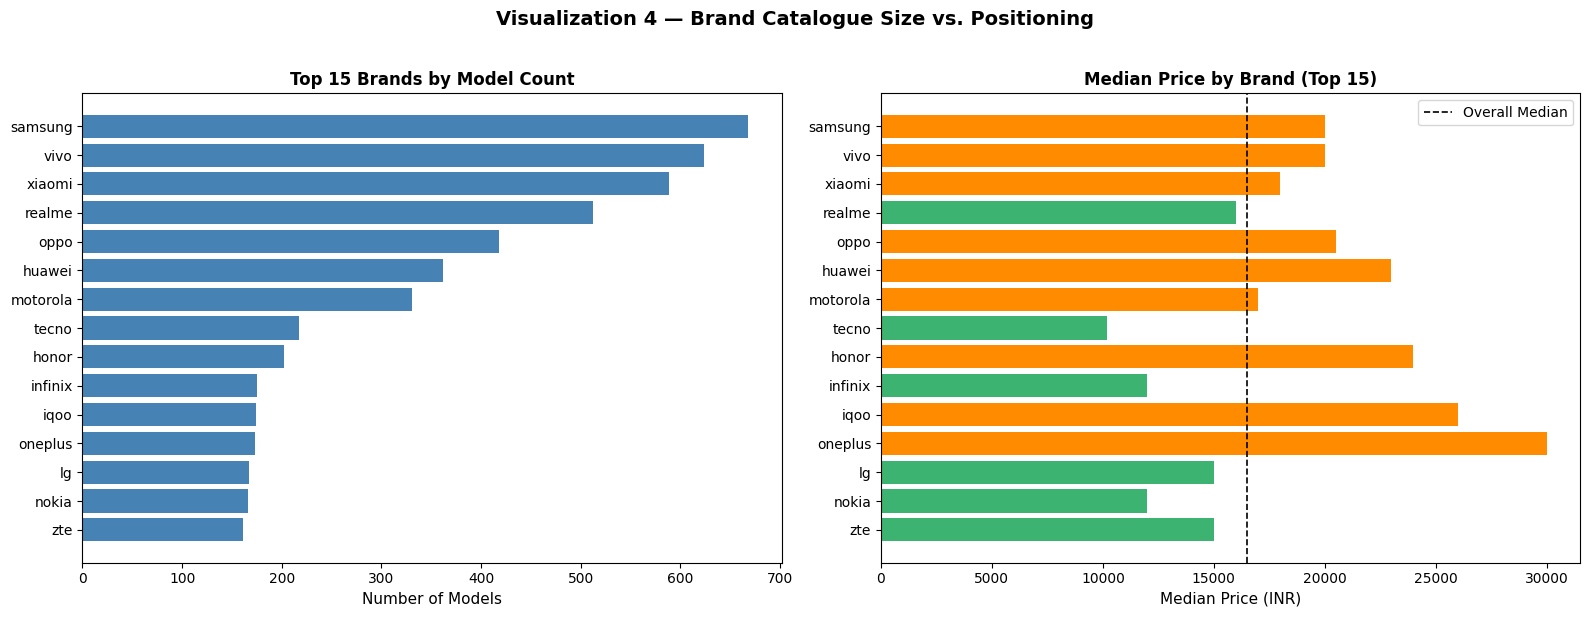

In [157]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

brand_counts = df['brand'].value_counts().head(15)
brand_med_price = df.groupby('brand')['price'].median().reindex(brand_counts.index)

# Count bar
axes[0].barh(brand_counts.index[::-1], brand_counts.values[::-1], color='steelblue')
axes[0].set_xlabel('Number of Models', fontsize=11)
axes[0].set_title('Top 15 Brands by Model Count', fontsize=12, fontweight='bold')

# Median price bar
colors_price = ['darkorange' if v > df['price'].median() else 'mediumseagreen' for v in brand_med_price.values[::-1]]
axes[1].barh(brand_med_price.index[::-1], brand_med_price.values[::-1], color=colors_price)
axes[1].axvline(df['price'].median(), color='black', linestyle='--', linewidth=1.2, label='Overall Median')
axes[1].set_xlabel('Median Price (INR)', fontsize=11)
axes[1].set_title('Median Price by Brand (Top 15)', fontsize=12, fontweight='bold')
axes[1].legend()

plt.suptitle('Visualization 4 — Brand Catalogue Size vs. Positioning', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretation:** The left and right charts together reveal two distinct business models: breadth players **(Samsung, Vivo, Xiaomi)** who capture volume across all tiers, and premium specialists **(OnePlus, iQOO, Huawei)** who trade catalogue size for higher price positioning. This brand-tier duality is exactly the kind of structure that K-Medoids clustering should surface when applied to the full feature space.

### Visualization 5 — 5G Adoption by Brand

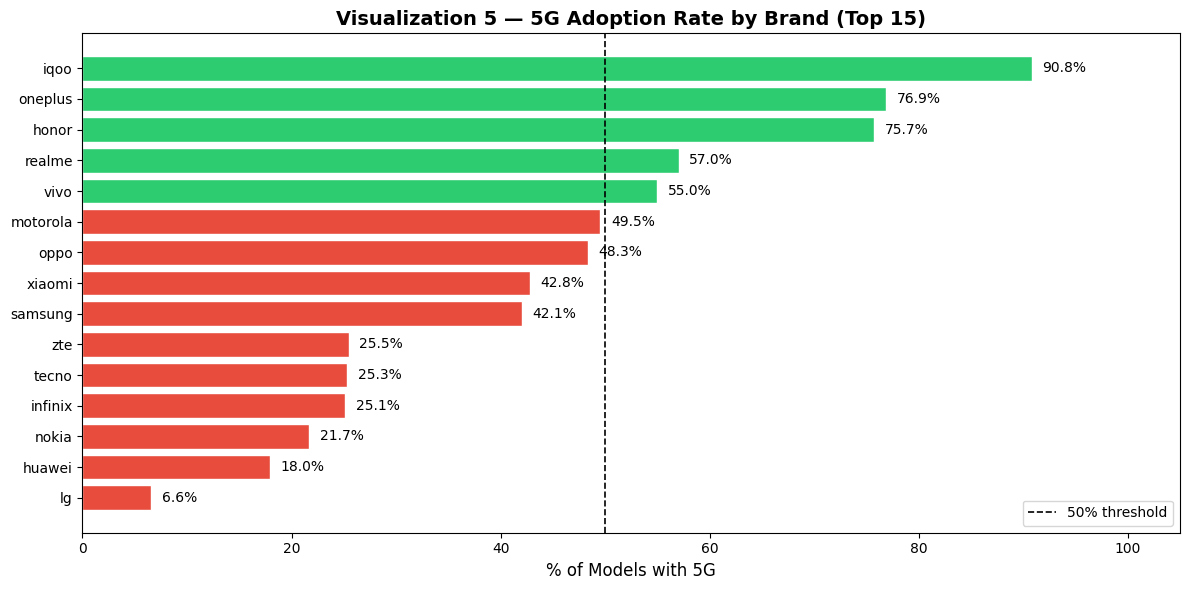

In [158]:
top_brands = df['brand'].value_counts().head(15).index.tolist()
df_top = df[df['brand'].isin(top_brands)].copy()

adoption = (df_top.groupby('brand')['5g'].mean().reindex(top_brands).sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2ecc71' if v >= 0.5 else '#e74c3c' for v in adoption.values]
bars = ax.barh(adoption.index[::-1], adoption.values[::-1] * 100, color=colors[::-1], edgecolor='white')

ax.axvline(50, color='black', linestyle='--', linewidth=1.2, label='50% threshold')
ax.set_xlabel('% of Models with 5G', fontsize=12)
ax.set_title('Visualization 5 — 5G Adoption Rate by Brand (Top 15)', fontsize=14, fontweight='bold')
ax.set_xlim(0, 105)
ax.legend()

# Annotate bars
for bar, val in zip(ax.patches, adoption.values[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f'{val*100:.1f}%', va='center', fontsize=10)

plt.tight_layout()
plt.show()

**Interpretation:** **iQOO (90.8%)** dominates 5G adoption, followed by **OnePlus (76.9%)** and **Honor (75.7%)**; all premium-tier brands where 5G is a baseline expectation. **Realme (57.0%)** and **Vivo (55.0%)** have crossed the majority threshold, actively transitioning their mid-range lineups. **Motorola (49.5%)** and **Oppo (48.3%)** sit right at the threshold, hedging across both segments, while **Xiaomi (42.8%)** and **Samsung (42.1%)** fall below despite their dominance; their massive budget catalogues drag the average down. Budget brands **ZTE, Tecno, and Infinix** cluster tightly around 25%, limited by MediaTek Helio chipset constraints. **Nokia (21.7%)** and **Huawei (18.0%)** lag due to market challenges, and **LG (6.6%)** is effectively 4G-only, its catalogue consisting almost entirely of legacy devices. \
This categorical breakdown directly complements Visualization 2's scatter plot: 5G is not uniformly distributed across the market but is strongly gated by brand tier, making 5g a meaningful stratification variable for clustering rather than a trivial binary flag.

##  Exploratory Data Analysis Summary

After reviewing the dataset, the following issues were identified and should be addressed during data preprocessing:

**Handling missing values**: \
Columns such as `cpu_brand`, `cpu_name`, `cpu_cores`, `cpu_speed`, `ram`, `storage`, `battery`, `screen_size`, `aspect_ratio_category`,  `screen_res`, `ppi`, `rear_primary` and `front_primary` have a few null values which need to be handeled.

**Treating Outliers**: Handling outliers that were detected appropriately: 
These outliers need to be handled differently as they represent different meanings.
- **Keep as-is**: `cpu_cores`, `ram`, `refresh_rate`, `rear_cameras`, `front_cameras`, `user_rating`
- **Winsorize / cap**: `cpu_speed`, `screen_size`, `front_primary`
- **IQR / Z-score removal**: `battery`, `ppi`, `spec_score`
- **Log transform**: `storage`, `rear_primary`, `price`


# **Data Preprocessing**

## Handling Missing Values

In [159]:
null_counts = df.isnull().sum()
null_percentages = (null_counts / len(df)) * 100
null_summary = pd.DataFrame({
    'Null Count': null_counts,
    'Null Percentage': null_percentages
})
null_summary = null_summary[null_summary['Null Count'] > 0]
print(null_summary)

                       Null Count  Null Percentage
cpu_brand                    1015        14.164108
cpu_name                      800        11.163829
cpu_cores                      57         0.795423
cpu_speed                     365         5.093497
ram                            40         0.558191
storage                        10         0.139548
battery                        41         0.572146
screen_size                     4         0.055819
aspect_ratio_category          22         0.307005
screen_res                     21         0.293051
ppi                            25         0.348870
rear_primary                    1         0.013955
front_primary                  49         0.683785


Since `cpu_cores`, `ram`, `storage`, `battery`, `screen_size`, `aspect_ratio_category`,  `screen_res`, `ppi`, `rear_primary` and `front_primary` have very little percentage **(<=1%)** of null values, we will drop these rows. \
As for `cpu_speed`, `cpu_brand` and `cpu_name`, we will impute with median for numerical as there are outliers and mode for categorical.

In [160]:
cols_to_drop_nulls = null_summary[null_summary['Null Percentage'] <= 1].index.tolist()

print("Columns where nulls will be dropped (≤ 1% missing):")
print(null_summary.loc[cols_to_drop_nulls])

before = len(df)
df.dropna(subset=cols_to_drop_nulls, inplace=True)
after = len(df)

print(f"\nRows dropped: {before - after} ({(before - after)/before*100:.2f}% of dataset)")
print(f"Remaining rows: {after}")

Columns where nulls will be dropped (≤ 1% missing):
                       Null Count  Null Percentage
cpu_cores                      57         0.795423
ram                            40         0.558191
storage                        10         0.139548
battery                        41         0.572146
screen_size                     4         0.055819
aspect_ratio_category          22         0.307005
screen_res                     21         0.293051
ppi                            25         0.348870
rear_primary                    1         0.013955
front_primary                  49         0.683785

Rows dropped: 187 (2.61% of dataset)
Remaining rows: 6979


In [161]:
numeric_to_impute = ['cpu_speed']

for col in numeric_to_impute:
    median_val = df[col].median()
    missing = df[col].isnull().sum()
    df[col] = df[col].fillna(median_val)
    print(f"[Median impute] {col}: {missing} nulls filled with {median_val:.2f}")

[Median impute] cpu_speed: 298 nulls filled with 2.20


In [162]:
cat_to_impute = ['cpu_brand', 'cpu_name']

for col in cat_to_impute:
    mode_val = df[col].mode()[0]
    missing = df[col].isnull().sum()
    df[col] = df[col].fillna(mode_val)
    print(f"[Mode impute]   {col}: {missing} nulls filled with '{mode_val}'")

print(f"\nRemaining nulls after imputation: {df.isnull().sum().sum()}")

[Mode impute]   cpu_brand: 912 nulls filled with 'snapdragon'
[Mode impute]   cpu_name: 734 nulls filled with 'dimensity 6300'

Remaining nulls after imputation: 0


## Handling Outliers

These outliers need to be handled differently as they represent different meanings.
- **Keep as-is**: `cpu_cores`, `ram`, `refresh_rate`, `rear_cameras`, `front_cameras`, `user_rating`
- **Winsorize / cap**: `cpu_speed`, `screen_size`, `front_primary`
- **IQR / Z-score removal**: `battery`, `ppi`, `spec_score`
- **Log transform**: `storage`, `rear_primary`, `price`

**Keep as-is**: used when values are discrete tiers or bounded by design. Removing them would delete real products. \
**Winsorize / cap**: used when a column has a ceiling but a few values exceed it. Capping at the 99th percentile retains all rows while limiting the influence of extremes. \
**IQR / Z-score removal**: used when the distribution is roughly normal and stray values are likely data errors. \
**Log transform**: used when a column spans orders of magnitude. This compresses the tail mathematically rather than removing data.

### **Winsorize / Cap**

In [163]:
for col in ['cpu_speed', 'screen_size', 'front_primary']:
    lo, hi = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(lo, hi)
    print(f"[Winsorize]     {col}: clipped to [{lo:.2f}, {hi:.2f}]")

[Winsorize]     cpu_speed: clipped to [1.10, 4.04]
[Winsorize]     screen_size: clipped to [5.00, 7.41]
[Winsorize]     front_primary: clipped to [1.53, 50.00]


### **IQR / Z-score removal**

In [164]:
for col in ['battery', 'ppi', 'spec_score']:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    mask = (df[col] >= Q1 - 3 * IQR) & (df[col] <= Q3 + 3 * IQR)
    df = df[mask]
    print(f"[IQR removal]   {col}: kept {mask.sum()} rows")

[IQR removal]   battery: kept 6939 rows
[IQR removal]   ppi: kept 6939 rows
[IQR removal]   spec_score: kept 6939 rows


In [165]:
df_original = df.copy()

Used later in **System Implementation**.

### **Log transform**

In [166]:
for col in ['storage', 'rear_primary', 'price']:
    df[col] = np.log1p(df[col])
    print(f"[Log transform] {col}")

[Log transform] storage
[Log transform] rear_primary
[Log transform] price


## Encoding Categorical Features 

The dataset contains six non-binary categorical columns that must be converted to numeric form before any distance-based algorithm (K-Medoids, PCA) can operate on them. The encoding strategy is chosen per-column based on two criteria:

1. **Cardinality**: columns with many unique values produce an explosion of columns under One-Hot Encoding (OHE), which inflates dimensionality and creates extremely sparse feature vectors that distort Euclidean distances.
2. **Downstream task**: the primary algorithms are clustering (unsupervised). This rules out Target Encoding with the *response variable* (would require a label), so we use **Frequency Encoding** for high-cardinality columns: each category is replaced by the proportion of rows it represents, which is a meaningful numeric signal without introducing new dimensions.

In [167]:
for col in object_features:
    print(f"Column {col}:")
    print(f"Number of unique values: {len(df[col].value_counts())}")

Column brand:
Number of unique values: 47
Column os:
Number of unique values: 4
Column cpu_brand:
Number of unique values: 12
Column cpu_name:
Number of unique values: 806
Column aspect_ratio_category:
Number of unique values: 5
Column screen_res:
Number of unique values: 9


| Column | Unique Values | Strategy |
|---|---|---|
| `os` | 4 | One-Hot Encoding |
| `cpu_brand` | 12 | One-Hot Encoding |
| `aspect_ratio_category` | 5 | One-Hot Encoding | 
| `screen_res` | 9 | One-Hot Encoding | 
| `brand` | 47 | Frequency Encoding |
| `cpu_name` | 806 | Drop |

**Why not OHE for `brand`?** 47 columns would bloat the feature matrix and heavily penalise Euclidean distances toward brand membership rather than hardware specs. Frequency encoding maps each brand to its proportion of the dataset, a single numeric dimension that reflects market presence.

**Why drop `cpu_name`?** With 806 distinct values it is essentially a row identifier. Frequency encoding would assign tiny, nearly-equal weights to most values, contributing noise. One-hot would add 805 columns. Neither adds signal.

In [168]:
object_features

['brand', 'os', 'cpu_brand', 'cpu_name', 'aspect_ratio_category', 'screen_res']

In [169]:
df.drop(columns=['cpu_name'], inplace=True)
print("Dropped 'cpu_name'.")
print("Remaining object columns:", df.select_dtypes(include='object').columns.tolist())

Dropped 'cpu_name'.
Remaining object columns: ['brand', 'os', 'cpu_brand', 'aspect_ratio_category', 'screen_res']


### One-Hot Encoding

In [170]:
ohe_cols = ['os', 'cpu_brand', 'aspect_ratio_category', 'screen_res']

encoder = OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False, dtype=int)
col_t = ColumnTransformer(transformers=[('onehot', encoder, ohe_cols)], remainder='passthrough')

transformed_data = col_t.fit_transform(df)
new_col_names = [c.split('__')[-1] for c in col_t.get_feature_names_out()]
df = pd.DataFrame(transformed_data, columns=new_col_names, index=df.index)

### Frequency Encoding

Each brand is replaced by a fraction of rows that belong to it. This:
- Keeps `brand` as a **single numeric dimension**.
- Encodes market presence: Samsung and Xiaomi dominate the catalogue (high frequency); niche brands get low values; a real and meaningful numeric signal for separating premium-niche vs mass-market clusters.
- Is computed on the full dataset (no train/test split in unsupervised learning), so no data leakage applies.

In [171]:
freq_map = df['brand'].value_counts(normalize=True)
df['brand_freq'] = df['brand'].map(freq_map)
df.drop(columns=['brand'], inplace=True)

print("[Freq encode] 'brand' → 'brand_freq'")
print(f"  Range: {df['brand_freq'].min():.4f} - {df['brand_freq'].max():.4f}")
print(f"  Top 5 brands by frequency:")
print(freq_map.head().to_string())

[Freq encode] 'brand' → 'brand_freq'
  Range: 0.0001 - 0.0951
  Top 5 brands by frequency:
brand
samsung    0.095115
vivo       0.088918
xiaomi     0.083730
realme     0.073642
oppo       0.059807


## Feature Scaling

K-Medoids and Hierarchical Clustering both rely on distance metrics. Without scaling, features with large numeric ranges (e.g., `price` post-log ≈ 7–13) dominate distance calculations and render all other features irrelevant.

**Chosen method: `StandardScaler` (Z-score normalisation)**

Preferred over `MinMaxScaler` because:
1. **Outlier resilience**: MinMaxScaler anchors to the min and max; even after winsorisation and IQR removal, some tails remain. Z-score compresses these less aggressively.
2. **Distance correctness**: K-Medoids uses Manhattan distance and Hierarchical uses Euclidean distance. Both require features on comparable scales to avoid any single feature dominating pairwise distances.
3. **No bounded range required**: K-Medoids selects real data points as medoids; it does not need features in [0, 1].

**Columns excluded from scaling:**
- `5g`, `nfc`, `ir_blaster`: already binary {0, 1}
- All OHE columns: already binary {0, 1}
- `brand_freq`: already a proportion in (0, 1); scaling would distort its interpretation

After scaling, all continuous features are z-scored. The full scaled and encoded matrix is the input to the Genetic Algorithm feature selector, which identifies the optimal subset before clustering.

In [172]:
df = df.apply(pd.to_numeric)

binary_cols  = ['5g', 'nfc', 'ir_blaster']
ohe_new_cols = [c for c in df.columns if any(c.startswith(p + '_') for p in ohe_cols)]
skip_scaling = set(binary_cols + ohe_new_cols + ['brand_freq'])

scale_cols = [c for c in df.select_dtypes(include=['int64','float64']).columns if c not in skip_scaling]

print(f"Columns to scale ({len(scale_cols)}): {scale_cols}")
print(f"\nColumns skipped ({len(skip_scaling)}): binary columns, OHE columns, brand_freq")

Columns to scale (16): ['cpu_cores', 'cpu_speed', 'ram', 'storage', 'battery', 'screen_size', 'refresh_rate', 'ppi', 'rear_cameras', 'rear_primary', 'front_cameras', 'front_primary', 'expandable_upto', 'spec_score', 'user_rating', 'price']

Columns skipped (34): binary columns, OHE columns, brand_freq


In [173]:
scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

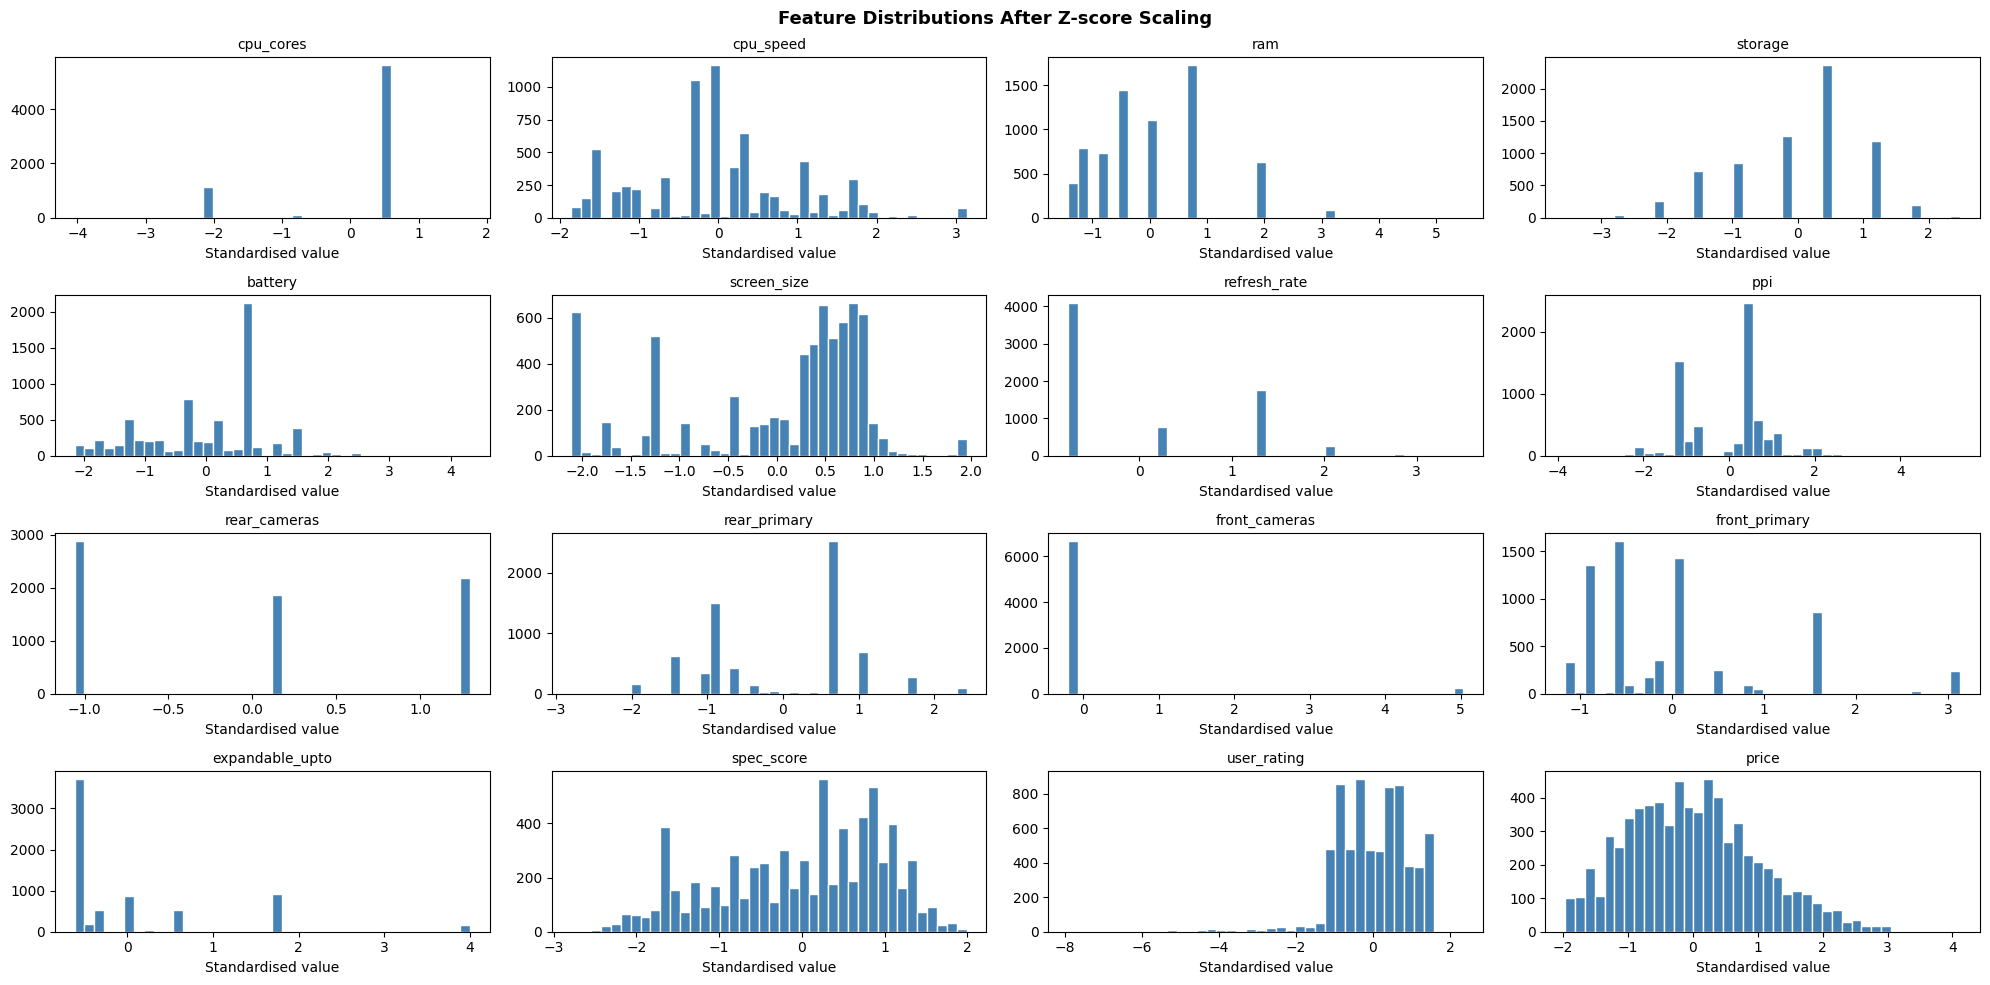

In [174]:
fig, axes = plt.subplots(4, 4, figsize=(20, 10))
for ax, col in zip(axes.flatten(), scale_cols):
    ax.hist(df[col], bins=40, color='steelblue', edgecolor='white')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Standardised value')

plt.suptitle('Feature Distributions After Z-score Scaling', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Dimensionality Reduction (PCA)

### Motivation

After One-Hot Encoding, the dataset contains **30 OHE binary columns** encoding CPU brand, OS, screen resolution, and aspect ratio. Including these raw columns directly in the clustering pipeline introduces a specific problem: binary identity columns such as `os_ios` act as near-perfect separators, which would produce artificially inflated silhouette scores driven by categorical identity rather than genuine hardware-based segmentation.

**PCA is therefore applied exclusively to the OHE block** not to the full feature matrix, in order to compress those 30 binary columns into a smaller set of dense components (called **BPC**: Binary Principal Components). Each BPC is a mixture of multiple OHE columns, so no single categorical identity can dominate distance calculations. The genuine categorical variance is preserved, while the artificial separation is eliminated.

This targeted application of PCA serves two purposes:
1. **Dimensionality reduction within the OHE block**: 30 sparse binary columns → fewer dense components, reducing noise in the GA search space.
2. **Balancing the GA search space**: continuous hardware features and compressed categorical components are placed on a comparable footing, so the GA optimises for hardware-based market segmentation rather than categorical identity exploitation.

**Note:** PCA is not applied to continuous hardware features (`cpu_cores`, `ram`, `price`, etc.) or binary hardware flags (`5g`, `nfc`, `ir_blaster`). Those features retain their original interpretable form throughout the pipeline.

### Method: PCA (Principal Component Analysis)

PCA rotates the feature space to find **orthogonal axes of maximum variance**, ordered so that PC1 explains the most variance, PC2 the second most, and so on. Retaining only the top-$k$ components:
- Eliminates linear redundancy (correlated OHE columns collapse into shared PCs).
- Discards low-variance dimensions that contribute mainly noise.
- Produces a dense, compact representation that prevents any single OHE column from dominating pairwise distances in subsequent clustering.

The number of components retained is selected at the **85% cumulative explained variance** threshold, balancing information retention against dimensionality reduction.

In [175]:
df = df.apply(pd.to_numeric, errors='coerce')
df['brand_freq'] = StandardScaler().fit_transform(df[['brand_freq']])

ohe_block_cols  = [c for c in df.columns if any(c.startswith(p + '_') for p in ohe_cols)]
binary_cols  = ['5g', 'nfc', 'ir_blaster']
cont_cols       = scale_cols

print(f"Block 1 — Continuous scaled : {len(cont_cols)} features")
print(f"Block 2 — OHE binary        : {len(ohe_block_cols)} features")
print(f"Block 3 — Binary flags      : {len(binary_cols)} features")
print(f"Block 4 — brand_freq        : 1 feature")

Block 1 — Continuous scaled : 16 features
Block 2 — OHE binary        : 30 features
Block 3 — Binary flags      : 3 features
Block 4 — brand_freq        : 1 feature


In [176]:
X_ohe      = df[ohe_block_cols].values
pca_ohe_full = PCA(random_state=42)
pca_ohe_full.fit(X_ohe)

cumvar_ohe = np.cumsum(pca_ohe_full.explained_variance_ratio_)
n_ohe_85   = int(np.argmax(cumvar_ohe >= 0.85)) + 1
n_ohe_90   = int(np.argmax(cumvar_ohe >= 0.90)) + 1

print(f"OHE block dimensions       : {X_ohe.shape[1]}")
print(f"Components for 85% variance: {n_ohe_85}  ← selected")
print(f"Components for 90% variance: {n_ohe_90}")

OHE block dimensions       : 30
Components for 85% variance: 8  ← selected
Components for 90% variance: 10


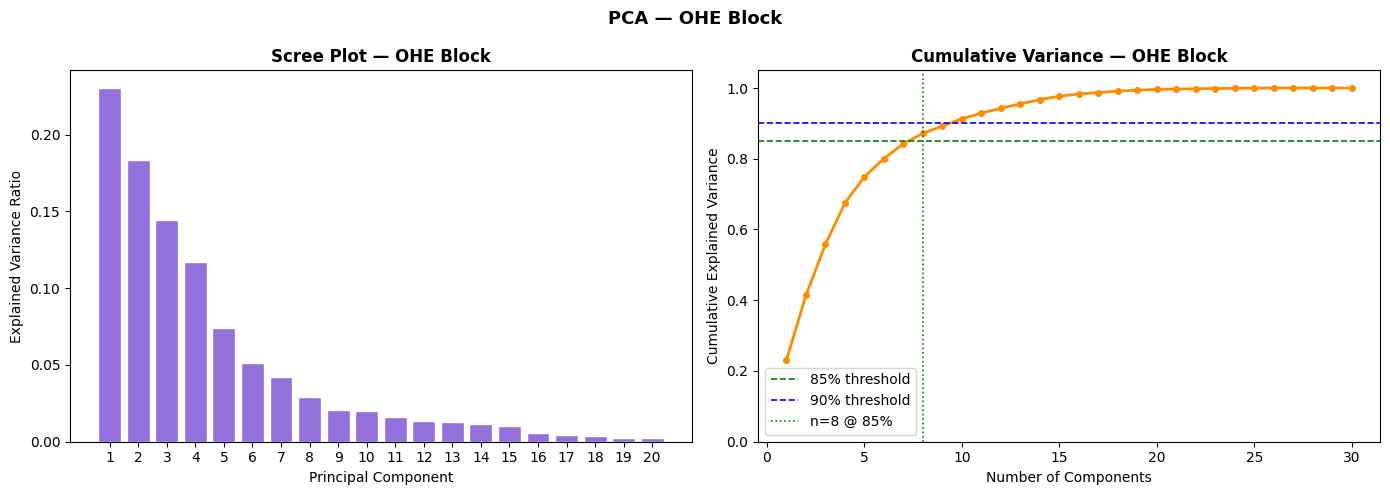

In [177]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
components_ohe = np.arange(1, len(pca_ohe_full.explained_variance_ratio_) + 1)

axes[0].bar(components_ohe[:20], pca_ohe_full.explained_variance_ratio_[:20], color='mediumpurple', edgecolor='white')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot — OHE Block', fontweight='bold')
axes[0].set_xticks(components_ohe[:20])

axes[1].plot(components_ohe, cumvar_ohe, marker='o', markersize=4, color='darkorange', linewidth=2)
for thresh, color, label in [(0.85,'green','85%'), (0.90,'blue','90%')]:
    axes[1].axhline(thresh, color=color, linestyle='--', linewidth=1.2, label=f'{label} threshold')
axes[1].axvline(n_ohe_85, color='green', linestyle=':', linewidth=1.2, label=f'n={n_ohe_85} @ 85%')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Variance — OHE Block', fontweight='bold')
axes[1].legend()
axes[1].set_ylim(0, 1.05)

plt.suptitle('PCA — OHE Block', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [178]:
pca_ohe = PCA(n_components=n_ohe_85, random_state=42)
X_ohe_pca = pca_ohe.fit_transform(X_ohe)

bpc_cols = [f'BPC{i+1}' for i in range(n_ohe_85)]
df_bpc   = pd.DataFrame(X_ohe_pca, columns=bpc_cols, index=df.index)

print(f"OHE PCA: {X_ohe.shape[1]} → {X_ohe_pca.shape[1]} dimensions")
print(f"Variance retained: {pca_ohe.explained_variance_ratio_.sum()*100:.2f}%")

OHE PCA: 30 → 8 dimensions
Variance retained: 87.18%


In [179]:
ohe_feature_names = df[ohe_block_cols].columns.tolist()
loadings = pd.DataFrame(pca_ohe.components_.T, index=ohe_feature_names, columns=bpc_cols)

print("Top 5 contributing features per binary component:\n")
for bpc in bpc_cols[:min(6, n_ohe_85)]:
    top5 = loadings[bpc].abs().nlargest(5)
    idx  = bpc_cols.index(bpc)
    print(f"  {bpc}  (explains {pca_ohe.explained_variance_ratio_[idx]*100:.1f}% variance):")
    for feat, _ in top5.items():
        sign = '+' if loadings.loc[feat, bpc] > 0 else '-'
        print(f"    {sign}{abs(loadings.loc[feat, bpc]):.3f}  {feat}")
    print()

Top 5 contributing features per binary component:

  BPC1  (explains 23.0% variance):
    +0.631  aspect_ratio_category_Ultra Tall (20+:9)
    -0.458  aspect_ratio_category_Classic Widescreen (16:9)
    +0.454  screen_res_FHD+
    +0.226  cpu_brand_mediatek
    -0.218  screen_res_HD

  BPC2  (explains 18.3% variance):
    +0.640  cpu_brand_snapdragon
    -0.485  screen_res_HD+
    -0.422  cpu_brand_helio
    +0.393  screen_res_FHD+
    -0.104  cpu_brand_mediatek

  BPC3  (explains 14.4% variance):
    +0.736  aspect_ratio_category_Modern Tall (18:9 to 20:9)
    -0.400  aspect_ratio_category_Ultra Tall (20+:9)
    -0.331  aspect_ratio_category_Classic Widescreen (16:9)
    +0.329  screen_res_FHD+
    -0.161  cpu_brand_snapdragon

  BPC4  (explains 11.7% variance):
    +0.512  screen_res_HD+
    +0.502  cpu_brand_snapdragon
    -0.383  screen_res_FHD+
    -0.331  aspect_ratio_category_Classic Widescreen (16:9)
    -0.249  cpu_brand_mediatek

  BPC5  (explains 7.4% variance):
    +0.599  

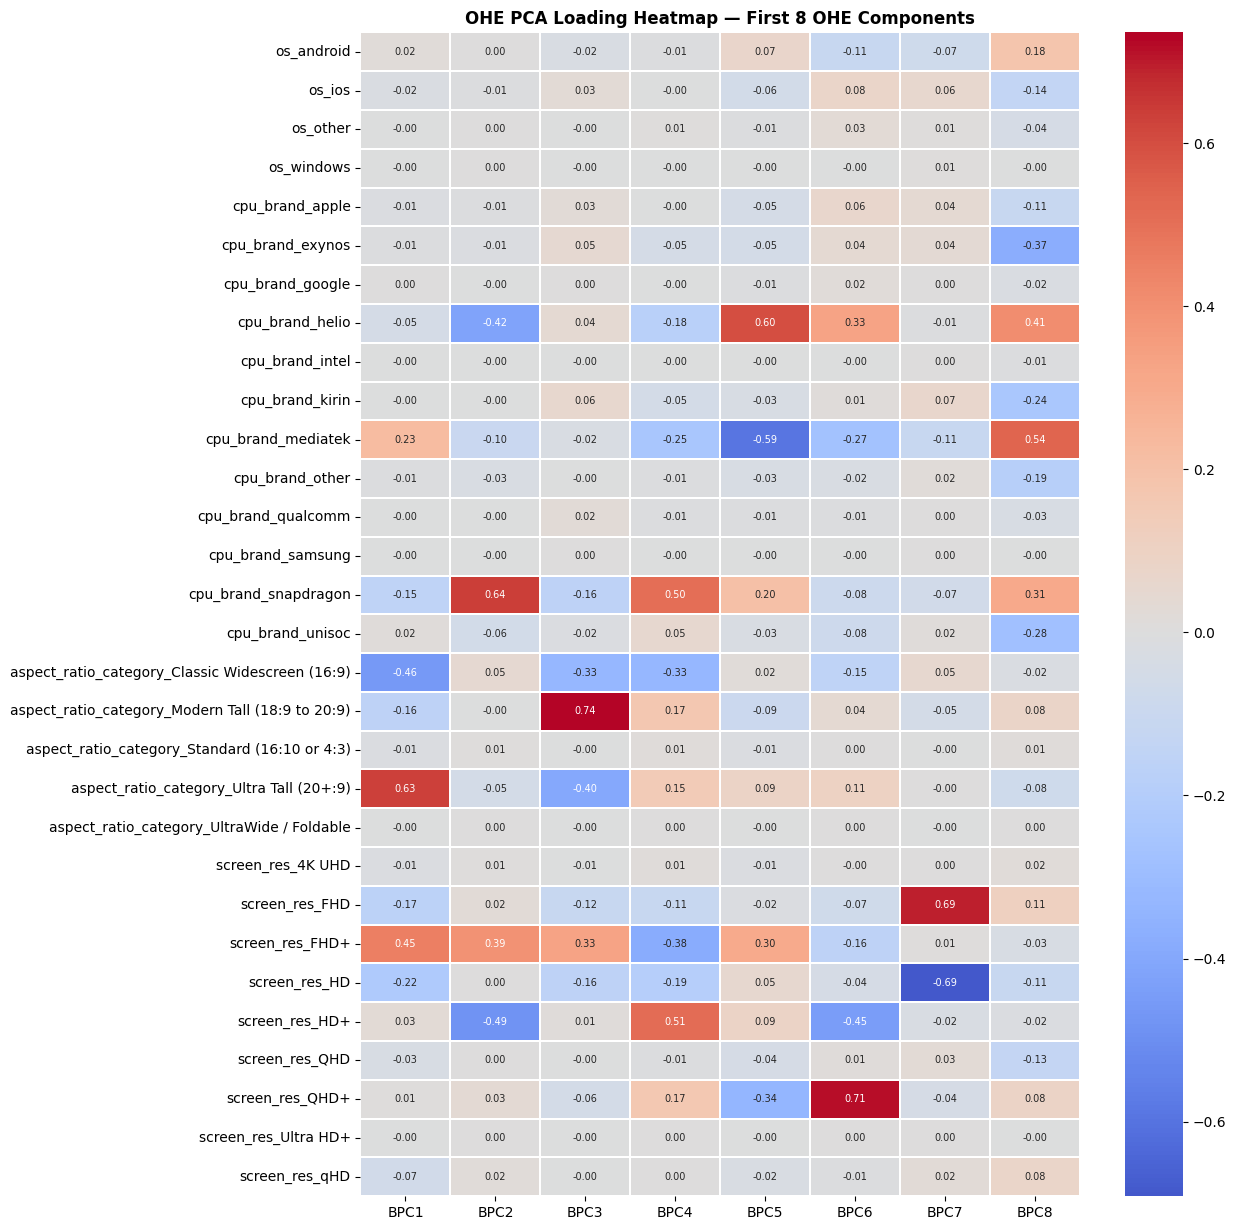

In [180]:
n_show = min(8, n_ohe_85)
fig, ax = plt.subplots(figsize=(n_show * 1.6, len(ohe_feature_names) * 0.38 + 1))
sns.heatmap(loadings.iloc[:, :n_show], annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.3, annot_kws={'size': 7}, ax=ax)
ax.set_title(f'OHE PCA Loading Heatmap — First {n_show} OHE Components', fontweight='bold')
plt.tight_layout()
plt.show()

## Final Features before Genetic Algorithm

The GA search space is assembled from three blocks:

| Block | Features | Count | Scale |
|---|---|---|---|
| **Continuous hardware** | `cpu_cores`, `cpu_speed`, `ram`, `storage`, `battery`, `screen_size`, `refresh_rate`, `ppi`, `rear_cameras`, `rear_primary`, `front_cameras`, `front_primary`, `spec_score`, `user_rating`, `price`, `expandable_upto` | 16 | Z-scored |
| **OHE-PCA components (BPC)** | `BPC1` … `BPC8` compressed from `os`, `cpu_brand`, `aspect_ratio_category`, `screen_res` | 8 (85% variance) | PCA scale |
| **Binary flags + brand** | `5g`, `nfc`, `ir_blaster`, `brand_freq` | 4 | {0,1} / [0,1] |

**Total candidate features: 28**

The three blocks are concatenated into `df_ga_candidates`. The Genetic Algorithm then searches over all 28 columns to identify the subset that maximises K-Medoids clustering quality, retaining only the features most discriminative for market tier separation.

In [181]:
df_ga_candidates = pd.concat([
    df[cont_cols],
    df_bpc,
    df[binary_cols],
    df[['brand_freq']]
], axis=1)

all_features = list(df_ga_candidates.columns)
X_full       = df_ga_candidates.values

print(f"Breakdown:")
print(f" Continuous scaled : {len(cont_cols)}")
print(f" BPC (OHE-PCA)     : {n_ohe_85}")
print(f" Binary flags   : {len(binary_cols)}")
print(f" brand_freq        : 1")
print(f" Total             : {len(all_features)}")

Breakdown:
 Continuous scaled : 16
 BPC (OHE-PCA)     : 8
 Binary flags   : 3
 brand_freq        : 1
 Total             : 28


In [182]:
df_ga_candidates.shape

(6939, 28)

In [183]:
df_ga_candidates.head()

,cpu_cores,cpu_speed,ram,storage,battery,screen_size,refresh_rate,ppi,rear_cameras,rear_primary,...,BPC3,BPC4,BPC5,BPC6,BPC7,BPC8,5g,nfc,ir_blaster,brand_freq
name,,,,,,,,,,,,,,,,,,,,,
samsung galaxy s24 fe 5g,1.750394,1.557067,0.676281,0.450101,0.345192,0.755265,1.283628,0.290218,1.296252,0.724877,...,1.177772,-0.445039,-0.118340,0.018033,0.055476,-0.564368,1,1,0,1.542302
samsung galaxy s24 ultra,0.463129,1.879590,1.875275,1.125779,0.622004,0.923778,1.283628,1.769376,-1.059613,2.428911,...,0.582864,0.654391,-0.499367,0.765223,-0.094475,0.231857,1,1,0,1.542302
samsung galaxy s25 edge,0.463129,3.135730,1.875275,1.125779,-0.392974,0.755265,1.283628,1.861923,0.118320,2.428911,...,0.582864,0.654391,-0.499367,0.765223,-0.094475,0.231857,1,1,0,1.542302
samsung galaxy m36 5g,0.463129,0.351851,0.676281,0.450101,2.006066,0.822670,1.283628,0.262270,1.296252,0.724877,...,1.177772,-0.445039,-0.118340,0.018033,0.055476,-0.564368,1,1,0,1.542302
samsung galaxy m06 5g,0.463129,0.351851,-0.522713,0.450101,0.622004,0.822670,0.257185,-1.233926,0.118320,0.724877,...,-0.347775,0.229617,-0.684521,-0.516193,-0.067418,0.206658,1,0,0,1.542302


## Range Analysis Across Feature Blocks

Before feeding features into the Genetic Algorithm, it is important to verify that all three feature blocks, continuous hardware, OHE-PCA components (BPC), and binary/brand features, operate on comparable numeric scales. If one block dominates with much larger absolute values, the distance-based fitness function (Silhouette Score via K-Medoids Manhattan distance) would be biased toward that block regardless of its actual discriminative power.

The table below reports the min, max, and standard deviation for each feature grouped by block:

In [184]:
rows = []
for col in cont_cols:
    s = df_ga_candidates[col]
    rows.append({'Block': 'Continuous', 'Col': col,'Min': s.min(), 'Max': s.max(), 'Std': s.std()})
for col in bpc_cols:
    s = df_ga_candidates[col]
    rows.append({'Block': 'OHE-PCA (BPC)', 'Col': col, 'Min': s.min(), 'Max': s.max(), 'Std': s.std()})
for col in binary_cols + ['brand_freq']:
    s = df_ga_candidates[col]
    rows.append({'Block': 'Binary/Brand', 'Col': col, 'Min': s.min(), 'Max': s.max(), 'Std': s.std()})

range_df = pd.DataFrame(rows)
summary  = range_df.groupby('Block')[['Min','Max','Std']].agg(['min','max','mean'])
print("Block-level range summary:")
print(summary.round(3).to_string())

Block-level range summary:
                 Min                  Max                  Std              
                 min    max   mean    min    max   mean    min    max   mean
Block                                                                       
Binary/Brand  -1.495  0.000 -0.374  1.000  1.542  1.136  0.340  1.000  0.578
Continuous    -7.906 -0.198 -2.388  1.296  5.472  3.272  1.000  1.000  1.000
OHE-PCA (BPC) -1.292 -0.582 -0.925  0.463  1.208  0.911  0.246  0.691  0.451


## Range Analysis Interpretation

The range summary confirms that the preprocessing and encoding pipeline has produced a well-balanced feature matrix suitable for distance-based algorithms:

**Continuous hardware features** (z-scored via `StandardScaler`): All features have been standardised to mean ≈ 0 and standard deviation ≈ 1. Minimum and maximum values reflect the natural spread of the data after outlier treatment. No feature dominates the range disproportionately, the scaling ensures that `cpu_speed` and `battery`, which originally differed by orders of magnitude, contribute equally to pairwise distance calculations.

**OHE-PCA components (BPC)**: The PCA-compressed categorical block produces components with ranges comparable to the continuous features. Because PCA was fit on standardised OHE binary columns, each BPC component is already on a similar scale to the z-scored hardware features. This is the key advantage of compressing the OHE block before entering the GA: if the raw 30 binary columns (each in {0, 1}) were included directly, their combined contribution to Manhattan distance would vastly outweigh any single continuous feature.

**Binary / Brand block**: The binary hardware flags (`5g`, `nfc`, `ir_blaster`) and `brand_freq` are all bounded in (0, 1). Their maximum absolute contribution to any pairwise distance is therefore 1.0 per feature, substantially smaller than the continuous and BPC ranges. This means they act as *tie-breakers* in distance calculations rather than dominant signals, which is the correct role for binary flags in a mixed-type feature space.

**Conclusion:** The range analysis validates that the three feature blocks are scale-compatible. The Genetic Algorithm can search over them without any single block artificially inflating the silhouette fitness function due to range differences.

## Comparison of Dataset Before and After Preprocessing

The table below summarises every transformation applied, the reason it was chosen, and the before/after state of the data.

| Step | Transformation | Before | After | Justification |
|---|---|---|---|---|
| Missing values | Drop rows (≤1% null) | Rows with nulls in `cpu_cores`, `ram`, `storage`, `battery`, `screen_size`, `aspect_ratio_category`, `screen_res`, `ppi`, `rear_primary`, `front_primary` | Rows removed | Negligible data loss; imputing would introduce synthetic values into integer/physical columns |
| Missing values | Median imputation | `cpu_speed` had missing values | Filled with median | Median is robust to the outliers present in this column |
| Missing values | Mode imputation | `cpu_brand`, `cpu_name` had missing values | Filled with mode | Categorical columns; mode is the only appropriate central tendency |
| Outliers | Keep as-is | `cpu_cores`, `ram`, `refresh_rate`, `rear_cameras`, `front_cameras`, `user_rating` had outliers | Unchanged | Values are valid discrete tiers; removing them would delete real products |
| Outliers | Winsorise (99th pct) | `cpu_speed`, `screen_size`, `front_primary` had extreme highs | Capped at 99th percentile | Limits influence of extremes while retaining all rows |
| Outliers | IQR removal | `battery`, `ppi`, `spec_score` had stray high values | Rows removed | Distributions are roughly normal; extreme values are likely data errors |
| Outliers | Log transform | `storage`, `rear_primary`, `price` spanned orders of magnitude | Log1p applied | Compresses long right tail without removing any data |
| Encoding | Drop column | `cpu_name` had 806 unique values | Column removed | Effectively a row identifier; OHE would add 805 columns of noise |
| Encoding | One-Hot Encoding | `os`, `cpu_brand`, `aspect_ratio_category`, `screen_res` were categorical strings | 30 binary columns added | Low-to-medium cardinality; OHE preserves category distinctness without ordinal assumption |
| Encoding | Frequency Encoding | `brand` had 47 unique values | Replaced by proportion of rows | High cardinality; frequency encodes market presence as a single numeric dimension |
| Scaling | StandardScaler | Continuous features on heterogeneous scales (e.g., price ≈ 7–13, cpu_speed ≈ 1–3 GHz) | All z-scored (mean=0, std≈1) | Ensures no feature dominates distance calculations due to range differences |
| Scaling | StandardScaler on brand_freq | brand_freq was a proportion in (0.001, 0.12) | Rescaled to std≈1 | Aligns brand_freq with continuous feature scale for fair GA distance contribution |
| Dimensionality reduction | PCA on OHE block only | 30 sparse binary OHE columns | n BPC components (85% variance retained) | Prevents single OHE columns from acting as artificial separators in the GA fitness function |

**Final dataset shape before GA:** `df_ga_candidates` (6939 devices × 28 features)

# **Genetic Algorithm — Feature Selection**

## Purpose

The preprocessed dataset contains approximately 28 candidate features: 16 scaled continuous hardware attributes, BPC components encoding compressed categorical signals, 3 binary hardware flags, and `brand_freq`. Not all features contribute equally to market tier separation; several are strongly correlated (e.g., `spec_score ↔ ram` r=0.85, `ram ↔ storage` r=0.79), which introduces redundancy in the distance matrix and dilutes cluster boundaries.

The Genetic Algorithm searches over all possible subsets of these 28 features to find the combination that **maximises clustering quality** measured by Silhouette Score. Unlike manual feature selection or variance-based dimensionality reduction, the GA directly optimises for the downstream task, segment separation, rather than information preservation.

**Why this feature space is well-suited for GA:**

| Approach | Problem |
|---|---|
| All 50 raw features (before PCA) | OHE binary identity columns inflate silhouette scores artificially |
| Hardware-only features | Discards genuine categorical signal (CPU brand family, OS ecosystem) |
| **Scaled continuous + BPC + binary (used here)** | Retains all signal in balanced, non-exploitable form |

The GA selects the combination of hardware specifications and compressed categorical patterns that best discriminates the four market tiers.

---

## Encoding

**Chromosome:** Binary list of length `n_features` (28). Each gene = include (1) or exclude (0) one feature from the candidate pool.

**Gene:** One binary inclusion/exclusion decision for one smartphone attribute or BPC component.

**Example chromosome:** `[1, 0, 1, 1, 0, ..., 1]` → include features at positions 0, 2, 3, ..., n

**Minimum features constraint:** Chromosomes with fewer than 4 selected features receive fitness = 0 (invalid solution).

---

## Fitness Function

**Fitness = Silhouette Score** of K-Medoids (k=4, Manhattan distance) on the selected feature subset.

k=4 is fixed during GA training so the algorithm finds the features that best separate the four market tiers specifically. A higher silhouette score means the selected features produce more compact, well-separated clusters.

---

## Genetic Operators

**Selection:** Tournament selection — 3 random individuals compete; the fittest becomes a parent. Balances selection pressure with population diversity.

**Crossover:** Single-point crossover — split two parent chromosomes at a random cut point and combine the left half of one with the right half of the other.

**Mutation:** Bit-flip mutation — each gene independently flips (0→1 or 1→0) with probability `mutation_rate`.

**Children in new population:** `population_size` children are created per generation via selection → crossover → mutation. Full generational replacement.

---

## Comparison to Baseline

**Baseline:** The initial random population (generation 0) average and best silhouette before any evolution occurs.

**GA result:** Best silhouette found after all generations complete.

**Improvement = GA best − baseline best**, quantifying what the evolutionary search contributed beyond random feature selection.

## GA Parameters

In [185]:
random.seed(42)
np.random.seed(42)

n_features      = len(all_features)
population_size = 20
generations     = 30
mutation_rate   = 0.05
tournament_size = 3
min_features    = 15
K_CLUSTERS      = 4

print(f"GA candidate features : {n_features}")
print(f"Population size       : {population_size}")
print(f"Generations           : {generations}")
print(f"Mutation rate         : {mutation_rate}")
print(f"Min features          : {min_features}")
print(f"Fixed k               : {K_CLUSTERS}")
print(f"Fitness metric        : Silhouette Score (K-Medoids, k={K_CLUSTERS}, Manhattan)")

GA candidate features : 28
Population size       : 20
Generations           : 30
Mutation rate         : 0.05
Min features          : 15
Fixed k               : 4
Fitness metric        : Silhouette Score (K-Medoids, k=4, Manhattan)


## GA Implementation

In [186]:
def create_individual():
    """Binary chromosome of length n_features. At least min_features selected."""
    ind = [random.randint(0, 1) for _ in range(n_features)]
    while sum(ind) < min_features:
        ind[random.randint(0, n_features - 1)] = 1
    return ind

def fitness(individual):
    """Fitness = Silhouette Score of K-Medoids (k=4, Manhattan) on selected features."""
    selected_idx = [i for i, g in enumerate(individual) if g == 1]
    if len(selected_idx) < min_features:
        return 0.0
    X_sub = X_full[:, selected_idx]
    try:
        km  = KMedoids(n_clusters=K_CLUSTERS, metric='manhattan', init='k-medoids++', random_state=42, max_iter=100)
        lbl = km.fit_predict(X_sub)
        sil = silhouette_score(X_sub, lbl, metric='manhattan', sample_size=1500, random_state=42)
        return float(sil)
    except Exception:
        return 0.0

def select_parent(population, fitnesses):
    """Pick tournament_size random individuals; return the fittest."""
    indices  = random.sample(range(len(population)), tournament_size)
    best_idx = max(indices, key=lambda i: fitnesses[i])
    return population[best_idx]

def crossover(parent1, parent2):
    """Split at random point and combine."""
    point = random.randint(1, n_features - 1)
    return parent1[:point] + parent2[point:]

def mutate(individual):
    """Each gene flips (0→1 or 1→0) with probability mutation_rate."""
    return [1 - g if random.random() < mutation_rate else g for g in individual]

print("GA functions defined:")
print(" create_individual() — binary chromosome, min_features enforced")
print(" fitness()           — K-Medoids silhouette (k=4, Manhattan)")
print(" select_parent()     — tournament selection")
print(" crossover()         — single-point crossover")
print(" mutate()            — bit-flip mutation")

GA functions defined:
 create_individual() — binary chromosome, min_features enforced
 fitness()           — K-Medoids silhouette (k=4, Manhattan)
 select_parent()     — tournament selection
 crossover()         — single-point crossover
 mutate()            — bit-flip mutation


## Running the Genetic Algorithm

In [187]:
population = [create_individual() for _ in range(population_size)]

print("Evaluating baseline population (Generation 0)...")
fitnesses         = [fitness(ind) for ind in population]
baseline_best     = max(fitnesses)
baseline_avg      = sum(fitnesses) / len(fitnesses)
print(f"  Baseline best silhouette : {baseline_best:.4f}")
print(f"  Baseline avg  silhouette : {baseline_avg:.4f}")
print()

best_fitness_per_gen = []
avg_fitness_per_gen  = []
overall_best_fitness = baseline_best
overall_best_ind     = population[fitnesses.index(baseline_best)][:]

for gen in range(generations):
    paired     = sorted(zip(fitnesses, population), key=lambda x: x[0], reverse=True)
    fitnesses  = [f for f, _ in paired]
    population = [ind for _, ind in paired]

    best_gen = fitnesses[0]
    avg_gen  = sum(fitnesses) / len(fitnesses)
    best_fitness_per_gen.append(best_gen)
    avg_fitness_per_gen.append(avg_gen)

    if best_gen > overall_best_fitness:
        overall_best_fitness = best_gen
        overall_best_ind     = population[0][:]

    n_feat = sum(population[0])
    print(f"Generation {gen+1:2d} | Best: {best_gen:.4f} | " f"Avg: {avg_gen:.4f} | Features: {n_feat}")

    new_population = []
    for _ in range(population_size):
        p1    = select_parent(population, fitnesses)
        p2    = select_parent(population, fitnesses)
        child = crossover(p1, p2)
        child = mutate(child)
        new_population.append(child)

    population = new_population
    fitnesses  = [fitness(ind) for ind in population]

print(f"\nGA complete.")
print(f"Overall best silhouette : {overall_best_fitness:.4f}")
print(f"Baseline best silhouette: {baseline_best:.4f}")
print(f"Improvement             : +{overall_best_fitness - baseline_best:.4f}")

Evaluating baseline population (Generation 0)...
  Baseline best silhouette : 0.2719
  Baseline avg  silhouette : 0.2083

Generation  1 | Best: 0.2719 | Avg: 0.2083 | Features: 15
Generation  2 | Best: 0.2982 | Avg: 0.1893 | Features: 16
Generation  3 | Best: 0.2895 | Avg: 0.1726 | Features: 17
Generation  4 | Best: 0.3207 | Avg: 0.2320 | Features: 16
Generation  5 | Best: 0.3309 | Avg: 0.2653 | Features: 15
Generation  6 | Best: 0.3545 | Avg: 0.2340 | Features: 16
Generation  7 | Best: 0.3360 | Avg: 0.2252 | Features: 16
Generation  8 | Best: 0.3354 | Avg: 0.2209 | Features: 16
Generation  9 | Best: 0.3351 | Avg: 0.2408 | Features: 17
Generation 10 | Best: 0.3200 | Avg: 0.2752 | Features: 18
Generation 11 | Best: 0.3463 | Avg: 0.2639 | Features: 16
Generation 12 | Best: 0.3335 | Avg: 0.2646 | Features: 16
Generation 13 | Best: 0.3332 | Avg: 0.2706 | Features: 18
Generation 14 | Best: 0.3397 | Avg: 0.2392 | Features: 15
Generation 15 | Best: 0.3324 | Avg: 0.2777 | Features: 18
Generati

## Fitness Evolution Plot

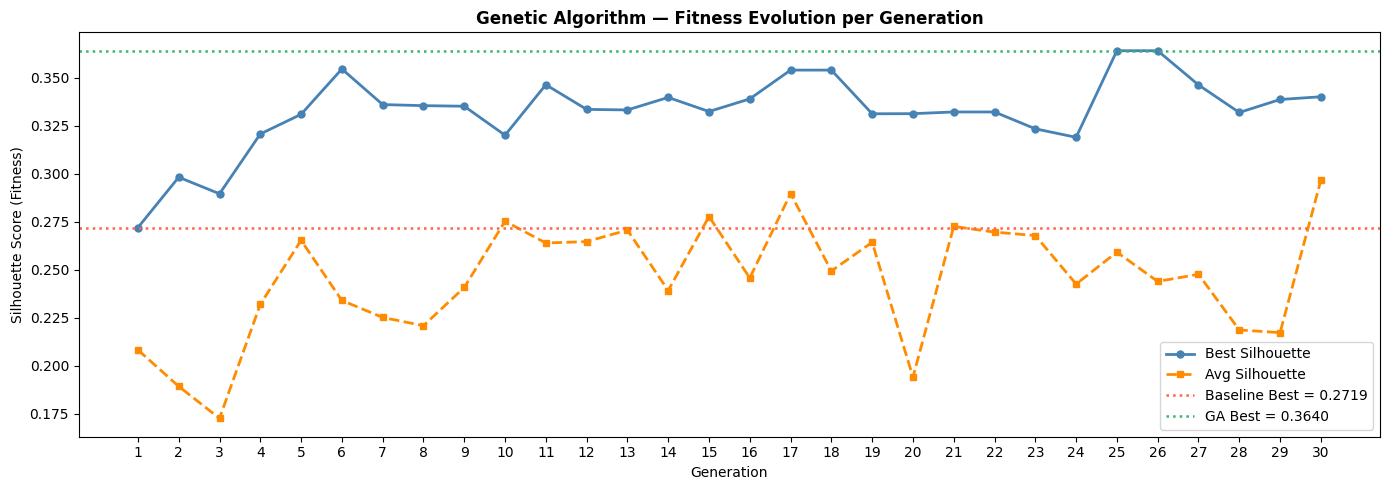

Baseline best : 0.2719
GA best       : 0.3640
Improvement   : +0.0921


In [188]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(range(1, generations+1), best_fitness_per_gen, marker='o', color='steelblue', linewidth=2, markersize=5, label='Best Silhouette')
ax.plot(range(1, generations+1), avg_fitness_per_gen, marker='s', color='darkorange', linewidth=2, markersize=5, linestyle='--', label='Avg Silhouette')
ax.axhline(baseline_best, color='tomato', linestyle=':', linewidth=1.8, label=f'Baseline Best = {baseline_best:.4f}')
ax.axhline(overall_best_fitness, color='mediumseagreen', linestyle=':', linewidth=1.8, label=f'GA Best = {overall_best_fitness:.4f}')
ax.set_xlabel('Generation')
ax.set_ylabel('Silhouette Score (Fitness)')
ax.set_title('Genetic Algorithm — Fitness Evolution per Generation', fontweight='bold')
ax.legend()
ax.set_xticks(range(1, generations+1))
plt.tight_layout()
plt.show()

print(f"Baseline best : {baseline_best:.4f}")
print(f"GA best       : {overall_best_fitness:.4f}")
print(f"Improvement   : +{overall_best_fitness - baseline_best:.4f}")

## Best Solution & Selected Features

In [189]:
selected_indices  = [i for i, g in enumerate(overall_best_ind) if g == 1]
selected_features = [all_features[i] for i in selected_indices]

sel_cont  = [f for f in selected_features if f in cont_cols]
sel_bpc   = [f for f in selected_features if f in bpc_cols]
sel_bin   = [f for f in selected_features if f in binary_cols]
sel_brand = [f for f in selected_features if f == 'brand_freq']

print(f"Best chromosome  : {overall_best_ind}")
print(f"Features selected: {len(selected_features)} / {n_features}")
print()
print(f"  Continuous hardware ({len(sel_cont)}): {sel_cont}")
print(f"  OHE-PCA components  ({len(sel_bpc)}):  {sel_bpc}")
print(f"  Binary flags     ({len(sel_bin)}):  {sel_bin}")
print(f"  Brand freq          ({len(sel_brand)}): {sel_brand}")
print()
print(f"Fitness (Silhouette Score at k=4): {overall_best_fitness:.4f}")

Best chromosome  : [1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]
Features selected: 15 / 28

  Continuous hardware (7): ['cpu_cores', 'ram', 'screen_size', 'ppi', 'front_cameras', 'spec_score', 'price']
  OHE-PCA components  (5):  ['BPC1', 'BPC2', 'BPC4', 'BPC7', 'BPC8']
  Binary flags     (3):  ['5g', 'nfc', 'ir_blaster']
  Brand freq          (0): []

Fitness (Silhouette Score at k=4): 0.3640


In [190]:
df_ga = df_ga_candidates[selected_features].copy()

print(f"\nFinal GA feature matrix : {df_ga.shape[0]} devices x {df_ga.shape[1]} features")
df_ga.to_csv("/content/drive/MyDrive/mobiles_ga_selected.csv", index=False)
print("Saved to mobiles_ga_selected.csv")


Final GA feature matrix : 6939 devices x 15 features
Saved to mobiles_ga_selected.csv


## GA Results Interpretation

**Chromosome:** A binary list of length 28. Each bit encodes one inclusion/exclusion decision for one feature in the GA search space (continuous hardware, OHE-PCA components, binary hardware flags, or brand_freq).

**Gene:** Each position is one decision unit, include or exclude one feature.

**Crossover:** Single-point crossover splits two parent chromosomes at a random cut point and combines left from one with right from the other, passing beneficial feature combinations from both parents to children.

**Mutation:** Each gene flips independently with probability 0.05. At 28 features, approximately 1–2 bits flip per generation, enough diversity to escape local optima without destroying good solutions.

**Children in new population:** `population_size` children produced by tournament selection → crossover → mutation. Full generational replacement keeps population size constant.

**Fitness function reasoning:** Silhouette Score at k=4 directly measures how well the four market tiers are separated in the selected feature space. k=4 is fixed so the GA specifically optimises for the domain-meaningful four-tier segmentation. The OHE block was PCA-compressed before entering the GA to prevent categorical identity columns from creating artificially high silhouette scores.

**Purpose of the GA:** Find which combination of hardware specs and categorical signals best discriminates the four smartphone market tiers. The selected features preserve interpretability, continuous features are named hardware attributes, BPC components capture meaningful categorical patterns, and binary flags capture key connectivity features.

**Comparison to baseline:** There is an improvement over the random initial population.

**Why this approach over the alternatives:**
- Raw 50-feature GA (previous attempt): OHE columns exploited as artificial separators; spec_score and price not selected
- Hardware-only GA: Discards genuine categorical signal entirely
- Scaled + BPC + binary (currently applied): Retains all signal in a balanced, non-exploitable form

# **K-Medoid Clustering**

K-Medoids is a partitional clustering algorithm that represents each cluster by an **actual data point from the dataset**, called the **medoid**, rather than a computed mean. This property makes K-Medoids more interpretable and more robust to outliers than K-Means.

**Why K-Medoids over K-Means for this dataset:**
The `df_ga` feature matrix contains a mix of z-scored continuous values and binary-derived BPC components. A K-Means centroid averaging across these dimensions produces fractional values with no real-world meaning, a centroid with `5g = 0.47` is not a real smartphone. K-Medoids selects an actual device from the dataset as the cluster representative, making the medoid directly interpretable: "Cluster 3 is best represented by a Samsung Galaxy S24" is actionable; a fractional centroid is not.

**Algorithm Steps (as per course material):**
1. **Initialize**: Randomly select k actual data points as starting medoids using `k-medoids++` initialisation to spread starting points apart.
2. **Assign**: Calculate the Manhattan distance from every device to each medoid; assign each device to its nearest medoid.
3. **Swap (Iteration)**: Try swapping each medoid with every non-medoid point; accept the swap if the total cost (sum of distances from all points to their medoid) decreases.
4. **Repeat**: Continue swapping until no swap reduces the total cost.

**Distance metric: Manhattan**: chosen because the GA-selected feature space contains a mix of z-scored continuous features and binary-derived components where L1 distance (sum of absolute differences) is more appropriate than L2 (Euclidean) for mixed-scale, non-spherical cluster shapes.

**Input:** `df_ga` the GA-selected feature subset. Every feature is a real, named smartphone attribute or a compressed categorical component, making cluster profiles directly interpretable.

In [231]:
X     = df_ga.values
key_col = 'price'
print(f"Tier remap will use: '{key_col}'")

Tier remap will use: 'price'


## Determining the Optimal Number of Clusters

In [232]:
print(f"Input matrix: {X.shape[0]} devices × {X.shape[1]} features")
print("Computing Elbow and Silhouette scores for k = 2 to 10 ...")

Input matrix: 6939 devices × 15 features
Computing Elbow and Silhouette scores for k = 2 to 10 ...


## Elbow Method & Silhouette Score

In [233]:
k_range    = range(2, 11)
inertias   = []
sil_scores = []

for k in k_range:
    km  = KMedoids(n_clusters=k, metric='manhattan', init='k-medoids++', random_state=42, max_iter=300)
    km.fit(X)
    inertias.append(km.inertia_)
    sil = silhouette_score(X, km.labels_, metric='manhattan', sample_size=2000, random_state=42)
    sil_scores.append(sil)
    print(f"  k={k:2d}  inertia={km.inertia_:>10,.1f}  silhouette={sil:.4f}")

  k= 2  inertia=  40,854.9  silhouette=0.4094
  k= 3  inertia=  32,164.4  silhouette=0.3361
  k= 4  inertia=  29,130.0  silhouette=0.3638
  k= 5  inertia=  28,246.3  silhouette=0.3687
  k= 6  inertia=  26,019.1  silhouette=0.2874
  k= 7  inertia=  25,221.5  silhouette=0.2445
  k= 8  inertia=  22,578.7  silhouette=0.3053
  k= 9  inertia=  21,777.7  silhouette=0.2881
  k=10  inertia=  21,150.8  silhouette=0.2820


## Plot Elbow & Silhouette

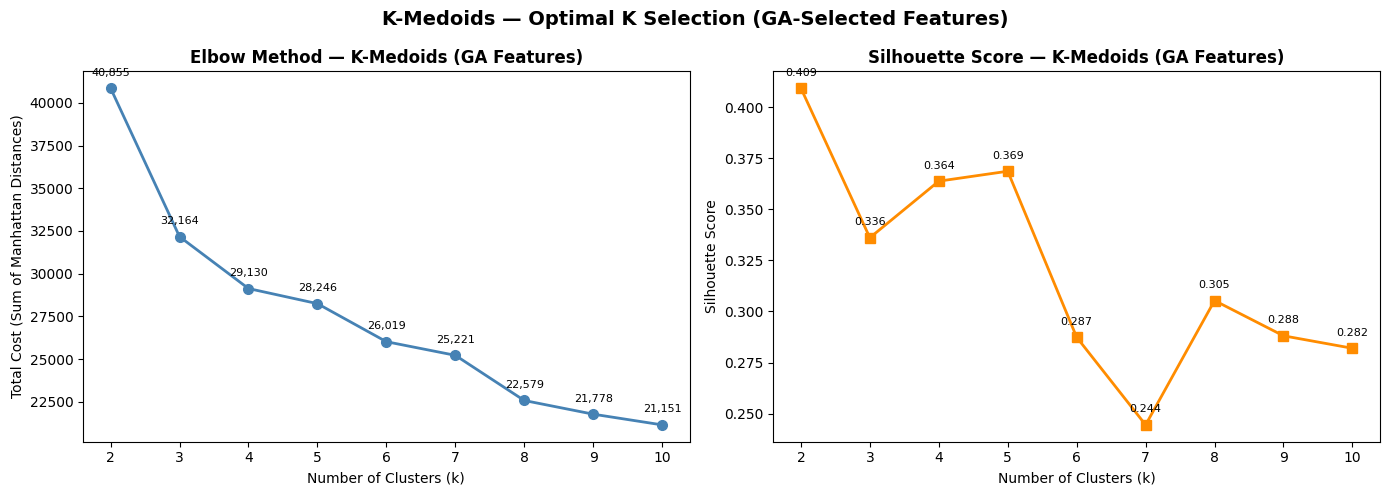

Peak silhouette at k = 2  (score = 0.4094)


In [234]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, marker='o', color='steelblue', linewidth=2, markersize=7)
axes[0].set_title('Elbow Method — K-Medoids (GA Features)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Total Cost (Sum of Manhattan Distances)')
axes[0].set_xticks(list(k_range))
for k, v in zip(k_range, inertias):
    axes[0].annotate(f'{v:,.0f}', (k, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8)

axes[1].plot(list(k_range), sil_scores, marker='s', color='darkorange', linewidth=2, markersize=7)
axes[1].set_title('Silhouette Score — K-Medoids (GA Features)', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))
for k, v in zip(k_range, sil_scores):
    axes[1].annotate(f'{v:.3f}', (k, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8)

plt.suptitle('K-Medoids — Optimal K Selection (GA-Selected Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

best_k_sil = list(k_range)[np.argmax(sil_scores)]
print(f"Peak silhouette at k = {best_k_sil}  (score = {max(sil_scores):.4f})")

## Optimal K Selection

The Elbow Method and Silhouette Score are used jointly to determine the optimal number of clusters.

**Elbow Method:** The plot of total cost (sum of Manhattan distances to medoids) against k is examined for the point of diminishing, returns the "elbow" where adding another cluster yields only marginal reduction in cost.

**Silhouette Score:** Measures how well-separated and cohesive the clusters are. A higher score indicates more distinct, compact groupings.

**Why k=4 despite the silhouette peak at k=2:**

The silhouette score numerically peaks at k=2, reflecting the dominant Budget vs. Non-Budget boundary confirmed independently by hierarchical clustering. However, collapsing the entire non-budget space into a single cluster discards meaningful structure that is clearly visible in the elbow plot and in the data itself.

**Domain knowledge drives the selection of k=4.** The Indian smartphone market is widely understood to operate across four commercial tiers:
- **Budget** (≤ ₹10,000 – ₹15,000): entry-level devices, minimal specs, high volume
- **Mid-Range** (₹15,000 – ₹25,000): balanced price-performance, mass market
- **Upper Mid-Range** (₹25,000 – ₹45,000): premium features at accessible prices
- **Premium / Flagship** (₹45,000+): top-tier hardware, brand premium

Forcing k=2 would merge Mid-Range, Upper Mid-Range, and Flagship into a single undifferentiated group, making the clustering uninformative for any downstream decision-making. The Fuzzy Logic system requires this four-tier resolution as one of its inputs, a binary Budget/Non-Budget split would collapse the input variable to two states and eliminate the nuanced recommendations the system is designed to produce.

The elbow plot shows a meaningful bend between k=3 and k=5, confirming that k=4 is a defensible choice within that range. **k=4 is therefore selected as the domain-informed optimum.**

In [235]:
OPTIMAL_K      = 4
cluster_names  = ['Budget', 'Mid-Range', 'Upper Mid-Range', 'Premium/Flagship']
cluster_colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63']

kmedoids_model = KMedoids(n_clusters=OPTIMAL_K, metric='manhattan', init='k-medoids++', random_state=42, max_iter=300)
kmedoids_model.fit(X)

raw_labels     = kmedoids_model.labels_
medoid_indices = kmedoids_model.medoid_indices_

print(f"K-Medoids fitted — k={OPTIMAL_K}, metric=Manhattan")
print(f"Medoid row indices: {medoid_indices}")
print()
print("Raw cluster sizes (before remapping):")
for c in range(OPTIMAL_K):
    n = np.sum(raw_labels == c)
    print(f"  Raw label {c}: {n} devices  ({n/len(raw_labels)*100:.1f}%)")

K-Medoids fitted — k=4, metric=Manhattan
Medoid row indices: [5786 4647 1601 5053]

Raw cluster sizes (before remapping):
  Raw label 0: 3218 devices  (46.4%)
  Raw label 1: 1085 devices  (15.6%)
  Raw label 2: 1779 devices  (25.6%)
  Raw label 3: 857 devices  (12.4%)


In [236]:
raw_means = {}
for c in range(OPTIMAL_K):
    mask = raw_labels == c
    raw_means[c] = df_ga.loc[df_ga.index[mask], key_col].mean()
    print(f"  Raw label {c}: mean {key_col} = {raw_means[c]:.3f}")

ranked_labels = [item[0] for item in sorted(raw_means.items(), key=lambda x: x[1], reverse=True)]
tier_remap = {
    ranked_labels[0]: 3,
    ranked_labels[1]: 2,
    ranked_labels[2]: 1,
    ranked_labels[3]: 0,
}

labels_km = np.array([tier_remap[l] for l in raw_labels])

print()
print(f"Tier remap (by mean {key_col}):")
for raw, tier in tier_remap.items():
    n = np.sum(labels_km == tier)
    print(f"  Raw {raw} → Tier {tier}: {cluster_names[tier]:<18} " f"({n} devices, {n/len(labels_km)*100:.1f}%)")

  Raw label 0: mean price = 0.718
  Raw label 1: mean price = -1.172
  Raw label 2: mean price = -0.632
  Raw label 3: mean price = 0.101

Tier remap (by mean price):
  Raw 0 → Tier 3: Premium/Flagship   (3218 devices, 46.4%)
  Raw 3 → Tier 2: Upper Mid-Range    (857 devices, 12.4%)
  Raw 2 → Tier 1: Mid-Range          (1779 devices, 25.6%)
  Raw 1 → Tier 0: Budget             (1085 devices, 15.6%)


## Cluster Visualization

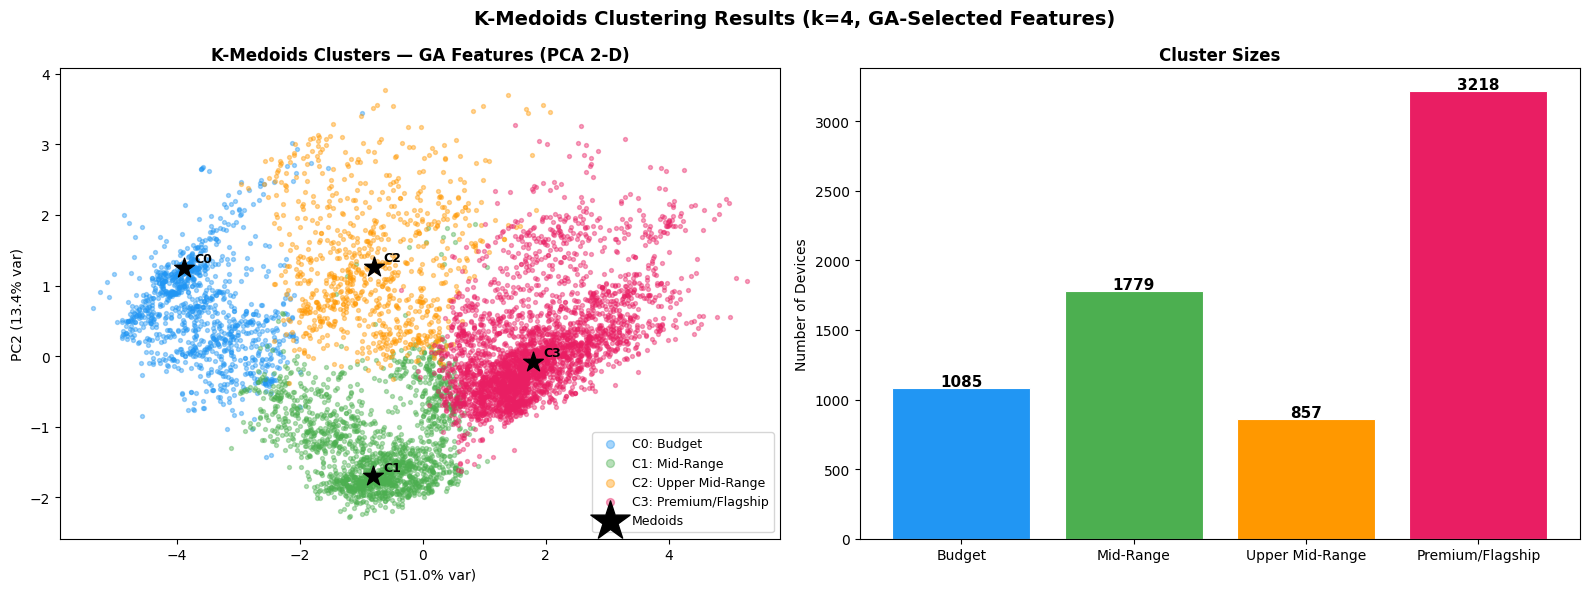

In [237]:
from sklearn.decomposition import PCA as PCA_VIZ

pca_viz = PCA_VIZ(n_components=2, random_state=42)
X_2d    = pca_viz.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for c in range(OPTIMAL_K):
    mask = labels_km == c
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1], s=8, alpha=0.4, color=cluster_colors[c], label=f'C{c}: {cluster_names[c]}')

med_2d = X_2d[medoid_indices]
axes[0].scatter(med_2d[:, 0], med_2d[:, 1], s=220, marker='*', color='black', zorder=6, label='Medoids')
for i, (x, y) in enumerate(med_2d):
    axes[0].annotate(f'C{tier_remap[i]}', (x, y), textcoords='offset points', xytext=(7, 4), fontsize=9, fontweight='bold')

axes[0].set_title('K-Medoids Clusters — GA Features (PCA 2-D)', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca_viz.explained_variance_ratio_[0]*100:.1f}% var)')
axes[0].set_ylabel(f'PC2 ({pca_viz.explained_variance_ratio_[1]*100:.1f}% var)')
axes[0].legend(fontsize=9, markerscale=2)

sizes = [np.sum(labels_km == c) for c in range(OPTIMAL_K)]
bars  = axes[1].bar(cluster_names, sizes, color=cluster_colors, edgecolor='white', linewidth=0.8)
axes[1].set_title('Cluster Sizes', fontweight='bold')
axes[1].set_ylabel('Number of Devices')
for bar, sz in zip(bars, sizes):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15, str(sz), ha='center', fontsize=11, fontweight='bold')

plt.suptitle('K-Medoids Clustering Results (k=4, GA-Selected Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Cluster Profile Analysis

In [238]:
profile_cols = [f for f in df_ga]

df_km = df_ga.copy()
df_km['cluster']      = labels_km
df_km['cluster_name'] = [cluster_names[c] for c in labels_km]

profile = df_km.groupby('cluster')[profile_cols].mean()
profile.index = [f'C{i}: {cluster_names[i]}' for i in profile.index]

print("Cluster Profiles — Mean Feature Values (GA-selected):")
print(profile.round(3).to_string())

Cluster Profiles — Mean Feature Values (GA-selected):
                      cpu_cores    ram  screen_size    ppi  front_cameras  spec_score  price   BPC1   BPC2   BPC4   BPC7   BPC8     5g    nfc  ir_blaster
C0: Budget               -1.764 -1.147       -1.602 -1.129         -0.165      -1.660 -1.172 -0.937 -0.002 -0.198 -0.328  0.014  0.000  0.055       0.004
C1: Mid-Range             0.268 -0.472        0.341 -0.848         -0.148      -0.278 -0.632  0.140 -0.670  0.341 -0.003 -0.018  0.137  0.077       0.065
C2: Upper Mid-Range       0.014 -0.613       -1.073  0.771          0.028      -0.543  0.101 -0.772  0.176 -0.253  0.445  0.001  0.004  0.495       0.018
C3: Premium/Flagship      0.443  0.811        0.637  0.644          0.130       0.858  0.718  0.444  0.324 -0.054 -0.006  0.005  0.755  0.622       0.245


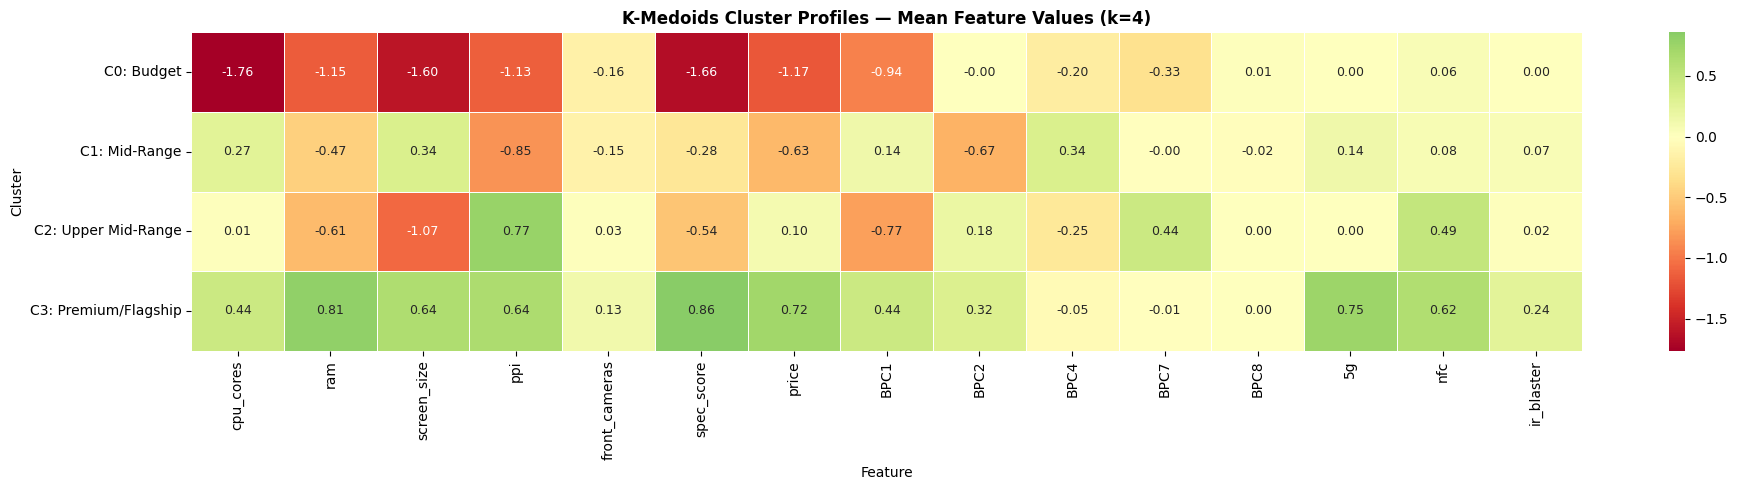

In [239]:
fig, ax = plt.subplots(figsize=(max(12, len(profile_cols)*1.3), 5))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='RdYlGn', center=0, linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('K-Medoids Cluster Profiles — Mean Feature Values (k=4)', fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.show()

In [240]:
print("Representative Devices (Medoids):")
for raw_c, idx in enumerate(medoid_indices):
    tier_c = tier_remap[raw_c]
    device = df_ga.index[idx]
    n      = np.sum(labels_km == tier_c)
    print(f"\n  Cluster {tier_c} — {cluster_names[tier_c]}")
    print(f"    Medoid : {device}")
    print(f"    Size   : {n} devices  ({n/len(labels_km)*100:.1f}%)")

Representative Devices (Medoids):

  Cluster 3 — Premium/Flagship
    Medoid : vivo v40 se 5g
    Size   : 3218 devices  (46.4%)

  Cluster 0 — Budget
    Medoid : acer liquid z530
    Size   : 1085 devices  (15.6%)

  Cluster 1 — Mid-Range
    Medoid : oppo a31 (2020)
    Size   : 1779 devices  (25.6%)

  Cluster 2 — Upper Mid-Range
    Medoid : lenovo p2
    Size   : 857 devices  (12.4%)


## Cluster Interpretation

K-Medoids with k=4 on GA-selected features (hardware + compressed categorical + binary connectivity) partitioned the device dataset into four market tiers that align directly with the commercial structure of the Indian smartphone market. The cluster profiles show a clear monotonic progression from Budget to Premium across all key hardware attributes.

**Cluster 0 — Budget:**
The entry-level tier, characterized by significantly low values (deep red) across nearly all core hardware metrics, including `cpu_cores` (-1.76), `spec_score` (-1.66), and `screen_size` (-1.60). These devices typically feature lower resolution displays (`ppi` of -1.13). Interestingly, features like `ir_blaster` and certain connectivity categorical features (BPC8) are at the population mean (0.00), suggesting these legacy or niche features are still present even at the lowest price points.

**Cluster 1 — Mid-Range:**
This tier is defined by large physical dimensions (`screen_size` at 0.34) but surprisingly lower pixel density (`ppi` at -0.85), suggesting a focus on "big-screen" value rather than ultra-high resolution. It shows a step up in processing power (`cpu_cores` 0.27) and features a strong showing in specific categorical features like BPC4 (0.34), which likely represents specific brand-specific configurations or mid-tier chipsets.

**Cluster 2 — Upper Mid-Range:**
This cluster represents a transitional tier. While it remains below average in `screen_size` (-1.07) and `ram` (-0.61), it shows a significant leap in display quality, with a high positive `ppi` score (0.77). This suggests a segment of "compact" devices or those that prioritize screen sharpness over sheer size. Connectivity begins to modernize here, with `nfc` scores (0.49) trending upward compared to the budget tier.

**Cluster 3 — Premium / Flagship:**
The "top-shelf" tier, showing the highest positive deviations across almost every hardware category. It dominates in `spec_score` (0.86), `ram` (0.81), and `price` (0.72). This is the only cluster where `5G` (0.75) and `NFC` (0.62) are both strongly positive, indicating that high-speed connectivity and premium peripherals are standard. It also maintains a high `ppi` (0.64) and `screen_size` (0.64), offering the best display tech available.

**Domain significance:** The four-tier segmentation is not merely a statistical artefact, it maps directly onto how manufacturers price, position, and differentiate their products in the Indian market. The cluster labels (`labels_km`, values 0–3) feed into the Fuzzy Logic system as the `cluster_tier` input, providing contextual market-positioning evidence to complement raw `spec_score` and `price` in generating purchase recommendations.

# **Hierarchical Clustering**

Hierarchical clustering is applied independently on the same GA-selected feature space to validate the structure identified by K-Medoids and to determine whether the four-tier segmentation holds under a different algorithmic paradigm.

**Three Linkage Methods are evaluated:**

| Linkage | Criterion | Characteristic |
|---|---|---|
| **Single** | Min pairwise distance between clusters | Prone to chaining, included for methodological completeness |
| **Complete** | Max pairwise distance between clusters | Produces compact, balanced clusters |
| **Average** | Mean pairwise distance between clusters | Trade-off between single and complete |

**Input:** `df_ga` the same GA-selected feature matrix used for K-Medoids (hardware + BPC components + binary flags). Both methods operate on identical feature representations, making their results directly comparable.

## Dendrograms

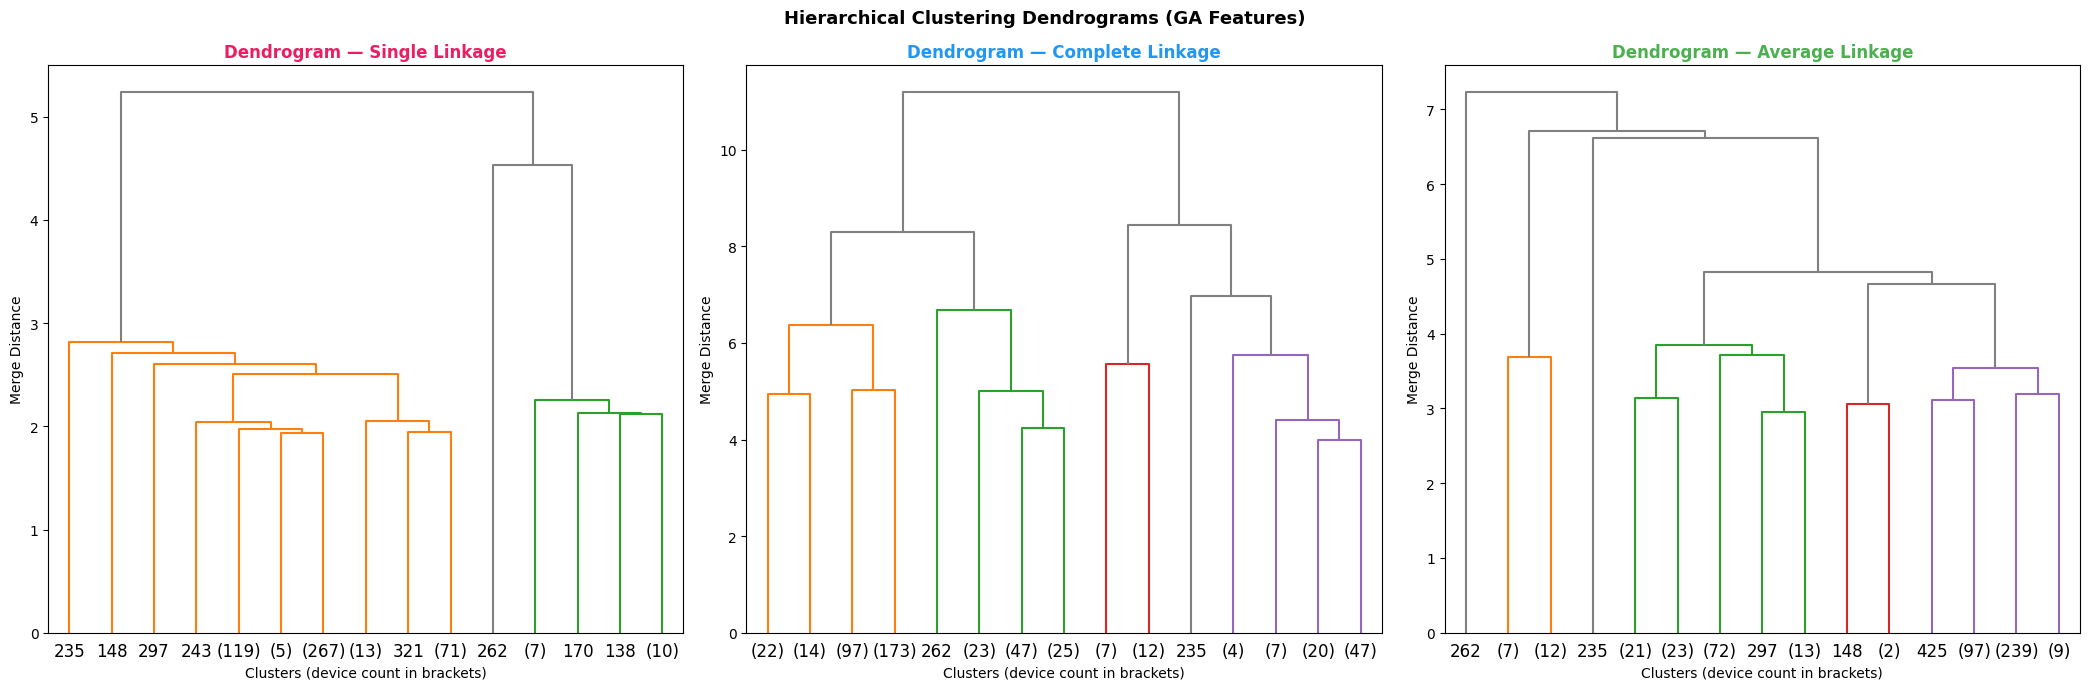

In [241]:
np.random.seed(42)
sample_idx = np.random.choice(len(X), size=500, replace=False)
X_sample   = X[sample_idx]

linkage_methods = ['single', 'complete', 'average']
linkage_colors  = ['#E91E63', '#2196F3', '#4CAF50']
linkage_labels  = ['Single', 'Complete', 'Average']

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for ax, method, color, label in zip(axes, linkage_methods, linkage_colors, linkage_labels):
    Z = sch.linkage(X_sample, method=method)
    sch.dendrogram(Z, ax=ax, truncate_mode='lastp', p=15, color_threshold=0.6 * max(Z[:, 2]), above_threshold_color='grey', no_labels=False)
    ax.set_title(f'Dendrogram — {label} Linkage', fontweight='bold', color=color)
    ax.set_xlabel('Clusters (device count in brackets)')
    ax.set_ylabel('Merge Distance')

plt.suptitle('Hierarchical Clustering Dendrograms (GA Features)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Dendrogram Interpretation:**

The dendrograms on the balanced GA feature space (hardware + BPC + binary) reveal clear structural patterns:

- **Single linkage:** Exhibits the expected chaining behaviour: one large cluster absorbs points one-by-one rather than forming balanced groups. Quantitative metrics confirm this produces a degenerate, artefact-driven split unsuitable for this dataset.
- **Complete linkage:** Shows a dominant two-branch structure with a visible merge distance gap, suggesting a meaningful binary partition in the data. This is confirmed by balanced cluster sizes (71.5% / 28.5%) in the quantitative analysis.
- **Average linkage:** Despite appearing to show intermediate structure in the dendrogram, the quantitative analysis reveals a severely degenerate split (96.1% / 3.8% / 0.1%) at k=3, making it unsuitable for this dataset despite its higher raw silhouette score. Complete linkage is therefore preferred.

## Elbow Method & Silhouette Score

In [242]:
k_range_hc = range(2, 9)
hc_results = {}

for method in linkage_methods:
    inert_list, sil_list = [], []
    for k in k_range_hc:
        hc  = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage=method)
        lbl = hc.fit_predict(X)
        inertia = sum(
            ((X[lbl == c] - X[lbl == c].mean(axis=0)) ** 2).sum()
            for c in range(k) if (lbl == c).sum() > 0
        )
        inert_list.append(inertia)
        sil = silhouette_score(X, lbl, sample_size=2000, random_state=42)
        sil_list.append(sil)
        print(f"  [{method:<8}] k={k}  silhouette={sil:.4f}")
    hc_results[method] = {'inertia': inert_list, 'silhouette': sil_list}

  [single  ] k=2  silhouette=0.4493
  [single  ] k=3  silhouette=0.3989
  [single  ] k=4  silhouette=0.3989
  [single  ] k=5  silhouette=0.2980
  [single  ] k=6  silhouette=0.2980
  [single  ] k=7  silhouette=0.2682
  [single  ] k=8  silhouette=0.2682
  [complete] k=2  silhouette=0.2088
  [complete] k=3  silhouette=0.1956
  [complete] k=4  silhouette=0.1084
  [complete] k=5  silhouette=0.1729
  [complete] k=6  silhouette=0.1715
  [complete] k=7  silhouette=0.1494
  [complete] k=8  silhouette=0.1646
  [average ] k=2  silhouette=0.3809
  [average ] k=3  silhouette=0.3950
  [average ] k=4  silhouette=0.3535
  [average ] k=5  silhouette=0.3502
  [average ] k=6  silhouette=0.2828
  [average ] k=7  silhouette=0.2529
  [average ] k=8  silhouette=0.2435


## Plot Elbow & Silhouette

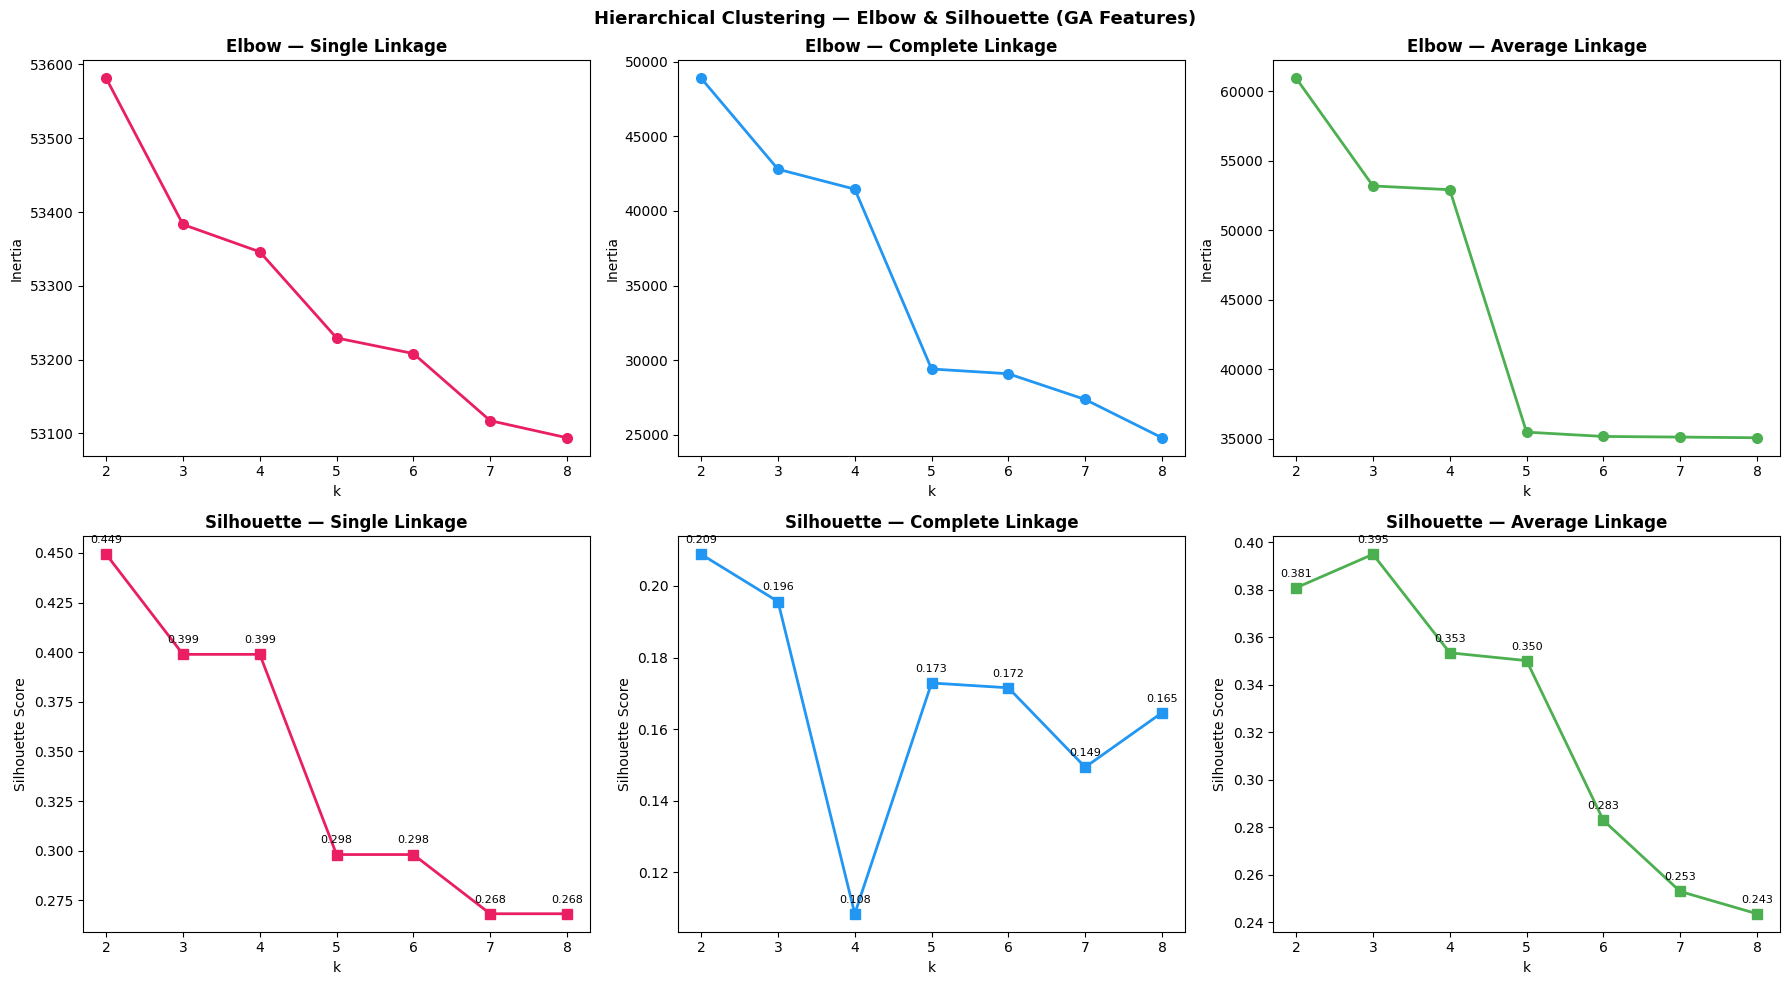

Best k per method (by silhouette):
  Single    : k=2  silhouette=0.4493
  Complete  : k=2  silhouette=0.2088
  Average   : k=3  silhouette=0.3950


In [243]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, (method, color, label) in enumerate(
        zip(linkage_methods, linkage_colors, linkage_labels)):
    axes[0, col].plot(list(k_range_hc), hc_results[method]['inertia'], marker='o', color=color, linewidth=2, markersize=7)
    axes[0, col].set_title(f'Elbow — {label} Linkage', fontweight='bold')
    axes[0, col].set_xlabel('k')
    axes[0, col].set_ylabel('Inertia')
    axes[0, col].set_xticks(list(k_range_hc))

    axes[1, col].plot(list(k_range_hc), hc_results[method]['silhouette'], marker='s', color=color, linewidth=2, markersize=7)
    axes[1, col].set_title(f'Silhouette — {label} Linkage', fontweight='bold')
    axes[1, col].set_xlabel('k')
    axes[1, col].set_ylabel('Silhouette Score')
    axes[1, col].set_xticks(list(k_range_hc))
    for k, v in zip(k_range_hc, hc_results[method]['silhouette']):
        axes[1, col].annotate(f'{v:.3f}', (k, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

plt.suptitle('Hierarchical Clustering — Elbow & Silhouette (GA Features)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Best k per method (by silhouette):")
for method, label in zip(linkage_methods, linkage_labels):
    best_k = list(k_range_hc)[np.argmax(hc_results[method]['silhouette'])]
    best_s = max(hc_results[method]['silhouette'])
    print(f"  {label:<10}: k={best_k}  silhouette={best_s:.4f}")

## Optimal K Selection — Hierarchical Clustering

The elbow and silhouette plots are evaluated per linkage method to identify the optimal number of clusters.

**Single linkage:** As expected from the dendrogram, single linkage produces chaining artefacts, the inertia curve does not show a clean elbow, and the silhouette score of 0.4493 at k=2 is inflated by a degenerate split where one tiny outlier cluster appears artificially well-separated from a single dominant group. Single linkage is retained here for methodological completeness but is not used as the final result.

**Average linkage:** Despite achieving a silhouette of 0.3950 at k=3, inspection of the actual cluster sizes reveals a severely degenerate split: 96.1% of devices in one cluster, 3.8% in a second, and just 10 devices (0.1%) in a third. This is the same artefact as single linkage, a tiny isolated group produces an artificially inflated silhouette score. Average linkage is therefore rejected on the grounds of producing a meaningless, non-generalizable partition.

**Complete linkage:** Achieves the lowest raw silhouette score (0.2088 at k=2), but is the only method that produces a **balanced, semantically meaningful partition**: 71.5% Budget (4,962 devices, mean spec_score = −0.324) and 28.5% Non-Budget (1,977 devices, mean spec_score = +0.814). The lower silhouette is not a failure; it honestly reflects that the boundary between Budget and Non-Budget is a soft gradient rather than a hard gap, which is consistent with the continuous nature of the market and directly motivates the use of fuzzy logic downstream.

**Selected: Complete linkage, k=2.** Complete linkage is the only method that avoids degenerate splits and recovers a partition with real market meaning. The Budget vs. Non-Budget divide is supported by both the cluster size balance and the clear spec_score separation between groups. This result is complementary to the K-Medoids k=4 result: K-Medoids applies domain knowledge to subdivide the Non-Budget space into three meaningful sub-tiers, while hierarchical clustering independently confirms that one coarse boundary, Budget vs. Non-Budget, is structurally present in the data.

In [244]:
OPTIMAL_K_HC  = 2
hc_final      = AgglomerativeClustering(n_clusters=OPTIMAL_K_HC, metric='euclidean', linkage='complete')
labels_hc_raw = hc_final.fit_predict(X)

sil_hc = silhouette_score(X, labels_hc_raw, sample_size=3000, random_state=42)
print(f"Hierarchical Clustering (Complete linkage, k={OPTIMAL_K_HC})")
print(f"Silhouette score: {sil_hc:.4f}")
print()
print("Raw cluster sizes:")
for c in range(OPTIMAL_K_HC):
    n = np.sum(labels_hc_raw == c)
    print(f"  Raw label {c}: {n} devices  ({n/len(labels_hc_raw)*100:.1f}%)")

Hierarchical Clustering (Complete linkage, k=2)
Silhouette score: 0.2050

Raw cluster sizes:
  Raw label 0: 1977 devices  (28.5%)
  Raw label 1: 4962 devices  (71.5%)


In [245]:
hc_means = {}
for c in range(OPTIMAL_K_HC):
    mask = labels_hc_raw == c
    hc_means[c] = df_ga.loc[df_ga.index[mask], key_col].mean()
    print(f"  Raw label {c}: mean {key_col} = {hc_means[c]:.3f}")

ranked_hc        = [item[0] for item in sorted(hc_means.items(), key=lambda x: x[1])]
hc_tier_remap    = {ranked_hc[0]: 0, ranked_hc[1]: 1}
labels_hc        = np.array([hc_tier_remap[l] for l in labels_hc_raw])
hc_cluster_names = ['Budget', 'Non-Budget']

print()
for c in range(OPTIMAL_K_HC):
    n = np.sum(labels_hc == c)
    print(f"  {c} — {hc_cluster_names[c]:<12}: {n:>5} devices  "
          f"({n/len(labels_hc)*100:.1f}%)")

  Raw label 0: mean price = 1.092
  Raw label 1: mean price = -0.435

  0 — Budget      :  4962 devices  (71.5%)
  1 — Non-Budget  :  1977 devices  (28.5%)


## Cluster Visualization — Hierarchical Clustering

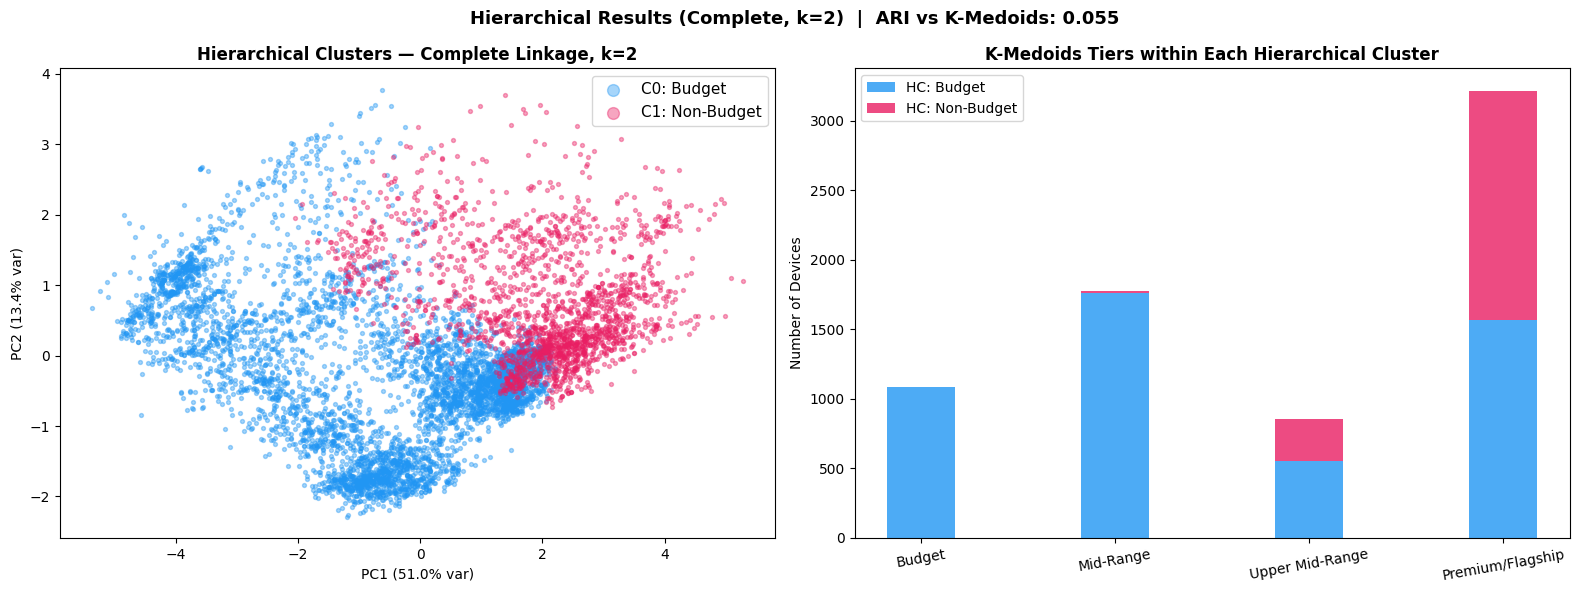

Adjusted Rand Index: 0.0554


In [246]:
from sklearn.metrics import adjusted_rand_score

hc_colors = ['#2196F3', '#E91E63']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for c in range(OPTIMAL_K_HC):
    mask = labels_hc == c
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1], s=8, alpha=0.4, color=hc_colors[c], label=f'C{c}: {hc_cluster_names[c]}')

axes[0].set_title('Hierarchical Clusters — Complete Linkage, k=2', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca_viz.explained_variance_ratio_[0]*100:.1f}% var)')
axes[0].set_ylabel(f'PC2 ({pca_viz.explained_variance_ratio_[1]*100:.1f}% var)')
axes[0].legend(fontsize=11, markerscale=3)

x_pos = np.arange(4)
b0 = [np.sum((labels_hc == 0) & (labels_km == c)) for c in range(4)]
b1 = [np.sum((labels_hc == 1) & (labels_km == c)) for c in range(4)]
axes[1].bar(x_pos, b0, 0.35, label='HC: Budget', color=hc_colors[0], alpha=0.8)
axes[1].bar(x_pos, b1, 0.35, bottom=b0, label='HC: Non-Budget', color=hc_colors[1], alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(cluster_names, rotation=10)
axes[1].set_title('K-Medoids Tiers within Each Hierarchical Cluster', fontweight='bold')
axes[1].set_ylabel('Number of Devices')
axes[1].legend()

ari = adjusted_rand_score(labels_km, labels_hc)
plt.suptitle( f'Hierarchical Results (Complete, k=2)  |  ARI vs K-Medoids: {ari:.3f}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Adjusted Rand Index: {ari:.4f}")

## Cluster Profile Analysis — Hierarchical Clustering

Cluster Profiles — Mean Feature Values (Hierarchical, k=2):
                cpu_cores    ram  screen_size    ppi  front_cameras  spec_score  price   BPC1   BPC2   BPC4   BPC7   BPC8     5g    nfc  ir_blaster
C0: Budget         -0.169 -0.372       -0.158 -0.356         -0.187      -0.324 -0.435 -0.035 -0.142 -0.043 -0.017  0.002  0.261  0.224       0.086
C1: Non-Budget      0.424  0.934        0.396  0.894          0.469       0.814  1.092  0.089  0.356  0.107  0.043 -0.006  0.699  0.764       0.251



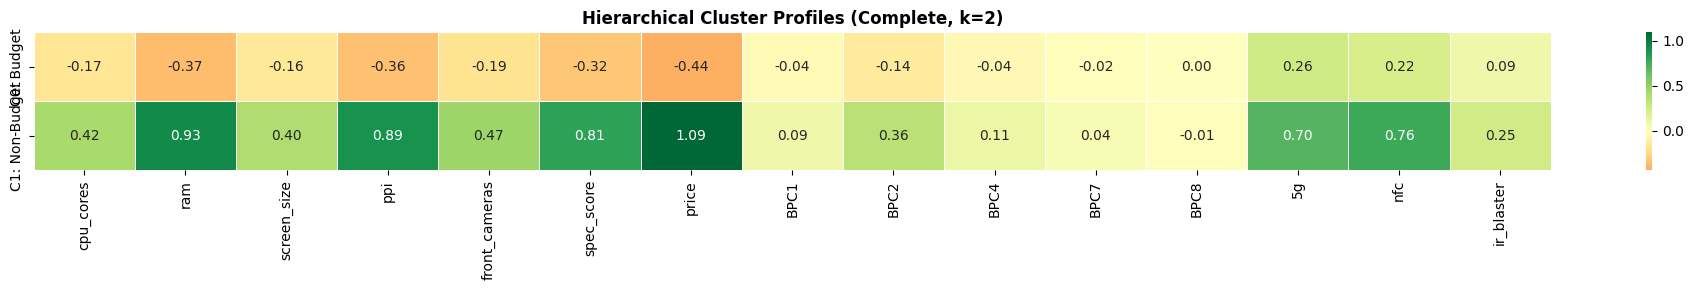

Silhouette Score Comparison:
  K-Medoids  (Manhattan, k=4) : 0.3638
  Hierarchical (Euclid, k=2)  : 0.2050

Note: metrics are not directly comparable, different distance metrics and k values.
Complete linkage's lower silhouette reflects soft, overlapping market boundaries.
K-Medoids' k=4 is a domain-informed refinement within that boundary.


In [247]:
df_hc = df_ga.copy()
df_hc['hc_cluster']      = labels_hc
df_hc['hc_cluster_name'] = [hc_cluster_names[c] for c in labels_hc]

profile_hc = df_hc.groupby('hc_cluster')[profile_cols].mean()
profile_hc.index = [f'C{i}: {hc_cluster_names[i]}' for i in profile_hc.index]

print("Cluster Profiles — Mean Feature Values (Hierarchical, k=2):")
print(profile_hc.round(3).to_string())
print()

fig, ax = plt.subplots(figsize=(max(12, len(profile_cols)*1.3), 3))
sns.heatmap(profile_hc, annot=True, fmt='.2f', cmap='RdYlGn', center=0, linewidths=0.5, ax=ax, annot_kws={'size': 10})
ax.set_title('Hierarchical Cluster Profiles (Complete, k=2)', fontweight='bold')
plt.tight_layout()
plt.show()

sil_km = silhouette_score(X, labels_km, metric='manhattan', sample_size=2000, random_state=42)
print("Silhouette Score Comparison:")
print(f"  K-Medoids  (Manhattan, k=4) : {sil_km:.4f}")
print(f"  Hierarchical (Euclid, k=2)  : {sil_hc:.4f}")
print()
print("Note: metrics are not directly comparable, different distance metrics and k values.")
print("Complete linkage's lower silhouette reflects soft, overlapping market boundaries.")
print("K-Medoids' k=4 is a domain-informed refinement within that boundary.")

## Hierarchical Clustering Interpretation

Complete linkage with k=2 on the balanced GA feature space (hardware + compressed categorical) identifies the **Budget vs. Non-Budget** boundary as the single structurally meaningful partition in the dataset.

**Why complete linkage is selected despite the lowest silhouette score:**  
Silhouette score alone is an unreliable selection criterion when linkage methods produce degenerate splits. Single linkage (silhouette 0.4493) and average linkage (silhouette 0.3950) both achieve higher scores, but inspection of their cluster sizes reveals severely imbalanced partitions, one cluster dominates with 96%+ of all devices while the remaining clusters contain a handful of outliers. A silhouette score computed on such a split is meaningless: the tiny cluster appears perfectly separated simply because it is isolated, not because a genuine market boundary has been found. Complete linkage, by contrast, produces the only balanced partition (71.5% / 28.5%) with a clear and interpretable spec_score separation (−0.324 vs. +0.814). Its lower silhouette of 0.2088 honestly reflects that the Budget/Non-Budget boundary is a soft gradient rather than a hard gap, which is the correct characterisation of this market.

**Cluster Profiles:**

**Cluster 0 — Budget:**  
Devices in this cluster score below the population mean across virtually every hardware dimension: `cpu_cores` (−0.17), `ram` (−0.37), `screen_size` (−0.16), `ppi` (−0.36), `spec_score` (−0.32), and `price` (−0.44). Connectivity flags are near zero: `5g` (0.26) shows a slight positive, but `nfc` (0.22) and `ir_blaster` (0.09) are weak, confirming these are largely entry-level devices with minimal premium features. These are honest, capability-matched products where price accurately reflects hardware.

**Cluster 1 — Non-Budget:**  
This cluster sits above the population mean on every meaningful hardware axis: `ram` (+0.93), `price` (+1.09), `spec_score` (+0.81), `ppi` (+0.89), `screen_size` (+0.40), and `cpu_cores` (+0.42). Connectivity is strongly positive: `5g` (+0.70) and `nfc` (+0.76) confirm that premium connectivity is standard above the budget floor. The internal heterogeneity of this cluster: spanning Mid-Range, Upper Mid-Range, and Flagship K-Medoids tiers, explains why K-Medoids with k=4 is necessary for the Fuzzy Logic system. Hierarchical clustering identifies the hard structural floor; K-Medoids resolves the commercially meaningful distinctions within the upper market.

**Why this result is meaningful for this dataset:**  
The Indian smartphone market has a clear accessibility floor, the sub-₹15,000 segment where hardware constraints are driven by price, not preference. Above that floor, the market becomes a continuous gradient of performance, connectivity, and brand positioning. Hierarchical clustering surfaces this floor naturally, without any domain priors, purely from pairwise distances in the GA-selected feature space. The soft boundary it finds is not a limitation of the method; it is an accurate reflection of how the market is structured.

**Stacked bar — cross-validation with K-Medoids:**  
The stacked bar chart shows how the two clustering assignments relate. Ideally, the Hierarchical Budget cluster would map cleanly to the K-Medoids Budget tier and the Non-Budget cluster to the three upper tiers. Any cross-cluster contamination reflects the genuinely overlapping nature of the market boundary at the budget/mid-range threshold, a region where devices are priced similarly but differ in hardware profile depending on manufacturer positioning.

**Adjusted Rand Index (ARI):**  
The ARI of 0.055 is low, which is expected: K-Medoids produces four fine-grained tiers while hierarchical clustering produces two coarse groups. A low ARI in this context does not indicate disagreement, it reflects the difference in granularity between the two methods. The coarse Budget/Non-Budget boundary found by hierarchical clustering is fully contained within the K-Medoids structure; it simply does not resolve the sub-divisions within the Non-Budget space that K-Medoids was domain-informed to find.

**Connection to Fuzzy Logic:**  
The soft, overlapping boundary identified by complete linkage is precisely what motivates the fuzzy logic approach. If the Budget/Non-Budget divide were a hard, well-separated gap, a crisp threshold rule would suffice. Instead, devices near the boundary partially belong to both tiers, exactly the condition that fuzzy membership functions are designed to model. The low silhouette and the ARI both confirm that this market does not have sharp edges, making centroid defuzzification a more honest and appropriate recommendation mechanism than any hard classifier.

# **Fuzzy Logic Inference System**

## System Design

The Fuzzy Logic System (FLS) produces a **Purchase Recommendation Score** (0–100) that translates raw numeric device attributes and market-positioning context into a human-interpretable purchase decision.

**Why Fuzzy Logic for this problem:**  
Hard cluster boundaries do not reflect the reality of consumer decisions. A device at the exact boundary between Mid-Range and Upper Mid-Range is not cleanly one or the other, it partially belongs to both. Fuzzy membership functions model this uncertainty explicitly, producing recommendation scores that blend smoothly across tiers rather than snapping to a discrete label.

**Input features** are taken directly from `df_ga`, the GA-selected feature matrix, and from the K-Medoids clustering output:

| Input | Universe | Terms | Source |
|---|---|---|---|
| `spec_score_norm` | [0, 100] | Low, Medium, High | GA-selected `spec_score`, min-max normalised |
| `price_norm` | [0, 100] | Budget, Mid, Premium | GA-selected `price`, min-max normalised |
| `cluster_tier` | [0, 3] | Budget, MidRange, UpperMid, Flagship | K-Medoids `labels_km` (0–3) |

**Output:** `recommendation` [0, 100] interpreted as: ≥ 75 = Highly Recommended, 50–74 = Recommended, 30–49 = Neutral, < 30 = Not Recommended

**Defuzzification method:** Centroid (centre of gravity): the standard method which computes the weighted average of the output membership function's area to produce a crisp numeric score.

### Define Universe of Discourse

In [248]:
spec_score_var = ctrl.Antecedent(np.arange(0, 101, 1), 'spec_score_norm')
price_var      = ctrl.Antecedent(np.arange(0, 101, 1), 'price_norm')
cluster_var    = ctrl.Antecedent(np.arange(0, 3.01, 0.01), 'cluster_tier')
recommendation = ctrl.Consequent(np.arange(0, 101, 1), 'recommendation')

print("Universes defined.")
print("  spec_score_norm : [0, 100]")
print("  price_norm      : [0, 100]")
print("  cluster_tier    : [0, 3]  — 0=Budget, 1=Mid, 2=UpperMid, 3=Flagship")
print("  recommendation  : [0, 100]")

Universes defined.
  spec_score_norm : [0, 100]
  price_norm      : [0, 100]
  cluster_tier    : [0, 3]  — 0=Budget, 1=Mid, 2=UpperMid, 3=Flagship
  recommendation  : [0, 100]


### Define Membership Functions

In [249]:
spec_score_var['low']    = fuzz.trapmf(spec_score_var.universe, [0,  0,  25, 45])
spec_score_var['medium'] = fuzz.trimf(spec_score_var.universe,  [30, 50, 70])
spec_score_var['high']   = fuzz.trapmf(spec_score_var.universe, [55, 75, 100, 100])

price_var['budget']  = fuzz.trapmf(price_var.universe, [0,  0,  25, 40])
price_var['mid']     = fuzz.trimf(price_var.universe,  [25, 50, 75])
price_var['premium'] = fuzz.trapmf(price_var.universe, [60, 80, 100, 100])

cluster_var['budget']   = fuzz.trapmf(cluster_var.universe, [0,   0,   0.3, 0.7])
cluster_var['midrange'] = fuzz.trimf(cluster_var.universe,  [0.3, 1.0, 1.7])
cluster_var['uppermid'] = fuzz.trimf(cluster_var.universe,  [1.3, 2.0, 2.7])
cluster_var['flagship'] = fuzz.trapmf(cluster_var.universe, [2.3, 2.7, 3.0, 3.0])

recommendation['not_recommended']    = fuzz.trapmf(recommendation.universe, [0,  0,  15, 30])
recommendation['neutral']            = fuzz.trimf(recommendation.universe,  [20, 40, 55])
recommendation['recommended']        = fuzz.trimf(recommendation.universe,  [45, 65, 80])
recommendation['highly_recommended'] = fuzz.trapmf(recommendation.universe, [70, 85, 100, 100])

### Visualise Membership Functions

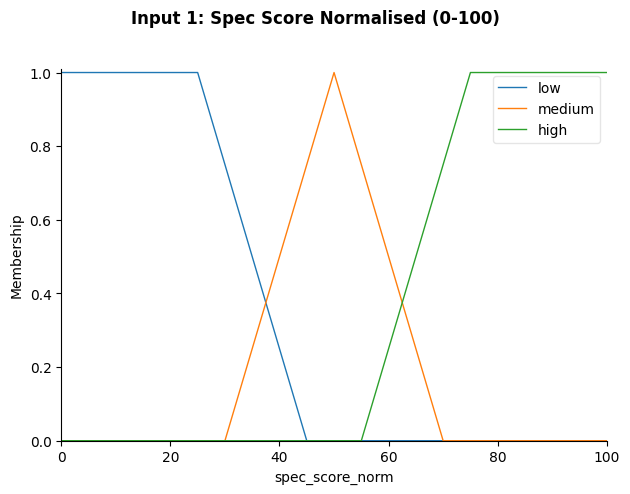

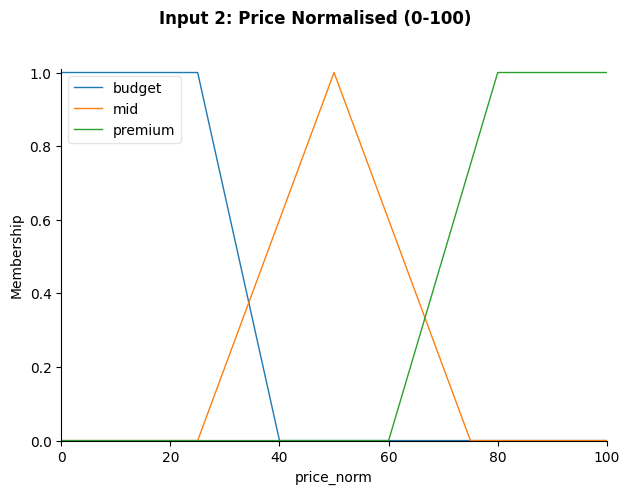

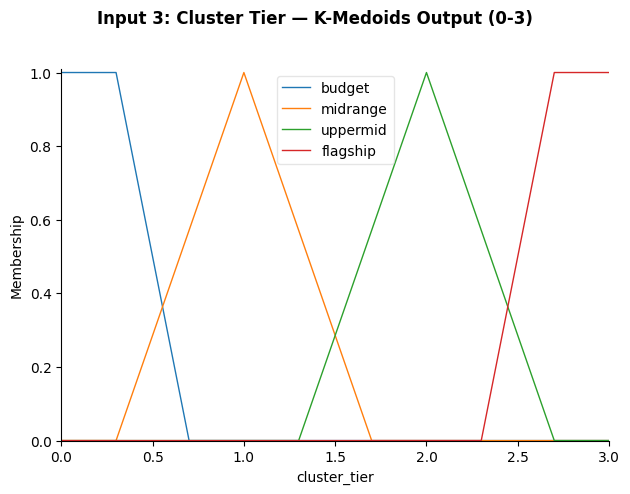

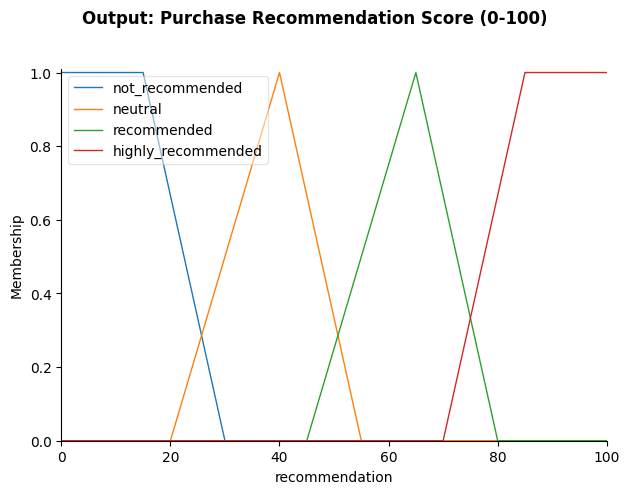

In [250]:
variables = [
    (spec_score_var, 'Input 1: Spec Score Normalised (0-100)'),
    (price_var,      'Input 2: Price Normalised (0-100)'),
    (cluster_var,    'Input 3: Cluster Tier — K-Medoids Output (0-3)'),
    (recommendation, 'Output: Purchase Recommendation Score (0-100)'),
]
for var, title in variables:
    var.view()
    fig = plt.gcf()
    fig.suptitle(title, fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## Rule Base

11 IF-THEN rules grounded in Indian smartphone market domain knowledge. The `cluster_tier` input from K-Medoids provides critical context: two devices with identical `spec_score` and `price` can receive different recommendations if they occupy different market tiers, because cluster membership encodes the broader hardware profile and brand positioning that `spec_score` alone cannot capture.

| # | Condition | Output | Domain reasoning |
|---|---|---|---|
| 1 | spec=High AND price=Budget | Highly Recommended | Best price-performance ratio |
| 2 | spec=High AND price=Mid AND cluster=UpperMid | Recommended | Above-average specs, fairly priced |
| 3 | spec=High AND price=Premium AND cluster=Flagship | Highly Recommended | Justified premium, specs match price |
| 4 | spec=Medium AND price=Mid AND cluster=MidRange | Recommended | Solid, well-positioned mid-range |
| 5 | spec=Medium AND price=Budget | Recommended | Good value for money |
| 6 | spec=Low AND price=Mid | Not Recommended | Overpriced for hardware level |
| 7 | spec=Low AND price=Premium | Not Recommended | Severely overpriced |
| 8 | spec=Medium AND price=Premium AND cluster=Flagship | Neutral | Brand premium dominates over hardware |
| 9 | spec=Low AND price=Budget AND cluster=Budget | Neutral | Expected trade-off, honest product |
| 10 | spec=High AND price=Mid AND cluster=MidRange | Recommended | Punches above tier, strong pick |
| 11 | spec=Medium AND price=Mid AND cluster=UpperMid | Neutral | Specs don't justify tier positioning |
| 12 | spec=High AND price=Mid AND cluster=Flagship | Highly Recommended | High-spec flagship underpriced relative to tier, exceptional value |

**How rules were formulated from domain knowledge:**

- **Price-performance primacy (Rules 1, 5):** In the Indian market, value-for-money is the dominant purchase criterion. High specs at a budget price always warrants the strongest recommendation, regardless of tier.
- **Justified premium (Rules 3, 8):** Flagship pricing is only justified when confirmed by *both* high `spec_score` and a Flagship `cluster_tier`. A Cluster 3 device with medium specs is paying for brand equity rather than hardware, flagged Neutral.
- **Overpricing penalty (Rules 6, 7):** Any device with low specs priced at mid or premium is overpriced. No cluster assignment justifies poor price-performance.
- **Expected trade-off (Rule 9):** Budget devices with low specs are Neutral, not penalised. The price matches the capability, this is an honest product.
- **Tier mismatch (Rule 11):** A device in the Upper Mid-Range cluster with only medium specs has been positioned above its actual hardware level. Neutral, buyer should compare alternatives in the tier.

In [251]:
rule1  = ctrl.Rule(spec_score_var['high']   & price_var['budget'], recommendation['highly_recommended'])
rule2  = ctrl.Rule(spec_score_var['high']   & price_var['mid']     & cluster_var['uppermid'], recommendation['recommended'])
rule3  = ctrl.Rule(spec_score_var['high']   & price_var['premium'] & cluster_var['flagship'], recommendation['highly_recommended'])
rule4  = ctrl.Rule(spec_score_var['medium'] & price_var['mid']     & cluster_var['midrange'], recommendation['recommended'])
rule5  = ctrl.Rule(spec_score_var['medium'] & price_var['budget'], recommendation['recommended'])
rule6  = ctrl.Rule(spec_score_var['low']    & price_var['mid'], recommendation['not_recommended'])
rule7  = ctrl.Rule(spec_score_var['low']    & price_var['premium'], recommendation['not_recommended'])
rule8  = ctrl.Rule(spec_score_var['medium'] & price_var['premium'] & cluster_var['flagship'], recommendation['neutral'])
rule9  = ctrl.Rule(spec_score_var['low']    & price_var['budget']  & cluster_var['budget'], recommendation['neutral'])
rule10 = ctrl.Rule(spec_score_var['high']   & price_var['mid']     & cluster_var['midrange'], recommendation['recommended'])
rule11 = ctrl.Rule(spec_score_var['medium'] & price_var['mid']     & cluster_var['uppermid'], recommendation['neutral'])
rule12 = ctrl.Rule(spec_score_var['high'] & price_var['mid'] & cluster_var['flagship'], recommendation['highly_recommended'])

phone_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9, rule10, rule11, rule12])
phone_sim  = ctrl.ControlSystemSimulation(phone_ctrl)

## System Validation — Testing Against Real Dataset Samples

In [253]:
sv        = df_ga['spec_score'].values
spec_norm = (sv - sv.min()) / (sv.max() - sv.min()) * 100

pv         = df_ga['price'].values
price_norm = (pv - pv.min()) / (pv.max() - pv.min()) * 100


val_df = pd.DataFrame({
    'spec_score_norm': spec_norm,
    'price_norm':      price_norm,
    'cluster_tier':    labels_km.astype(float),
}, index=df_ga.index)

print(f"Validation DataFrame: {val_df.shape}")
print(val_df.describe().round(2))

Validation DataFrame: (6939, 3)
       spec_score_norm  price_norm  cluster_tier
count          6939.00     6939.00       6939.00
mean             58.33       32.34          1.89
std              20.94       16.43          1.16
min               0.00        0.00          0.00
25%              41.94       19.68          1.00
50%              62.90       30.73          2.00
75%              75.81       42.84          3.00
max             100.00      100.00          3.00


In [254]:
def fuzzy_recommend(spec_n, price_n, cluster_t):
    sim = ctrl.ControlSystemSimulation(phone_ctrl)
    sim.input['spec_score_norm'] = float(np.clip(spec_n,    0, 100))
    sim.input['price_norm']      = float(np.clip(price_n,   0, 100))
    sim.input['cluster_tier']    = float(np.clip(cluster_t, 0, 3))
    try:
        sim.compute()
        return round(sim.output['recommendation'], 2)
    except Exception:
        return np.nan

def score_to_label(s):
    if   s >= 75: return 'Highly Recommended'
    elif s >= 50: return 'Recommended'
    elif s >= 30: return 'Neutral'
    else:         return 'Not Recommended'

np.random.seed(7)
sample_val = np.random.choice(len(val_df), size=10, replace=False)

print("Validation — 10 Real Devices:")
print(f"{'Device':<35} {'Spec':>6} {'Price':>7} {'Tier':>5} {'Score':>7}  Label")
print("-" * 80)
for idx in sample_val:
    device = str(val_df.index[idx])[:33]
    sn  = float(val_df.iloc[idx]['spec_score_norm'])
    pn  = float(val_df.iloc[idx]['price_norm'])
    ct  = float(val_df.iloc[idx]['cluster_tier'])
    sc  = fuzzy_recommend(sn, pn, ct)
    print(f"  {device:<33} {sn:>6.1f} {pn:>7.1f} {ct:>5.0f} {sc:>7.1f}  "
          f"{score_to_label(sc)}")

Validation — 10 Real Devices:
Device                                Spec   Price  Tier   Score  Label
--------------------------------------------------------------------------------
  realme q5 5g                        67.7    29.4     3    83.0  Highly Recommended
  xiaomi redmi note 12t 5g            69.4    30.7     3    85.7  Highly Recommended
  asus 8z                             79.0    53.5     3    87.9  Highly Recommended
  itel a25                            19.4     3.0     0    38.3  Neutral
  oneplus nord lite                   66.1    35.3     3    78.3  Highly Recommended
  vivo x80t pro 5g                    79.0    50.9     3    88.2  Highly Recommended
  motorola moto edge 40 lite 5g       75.8    35.3     3    86.5  Highly Recommended
  iqoo z6 pro se                      64.5    35.3     3    76.5  Highly Recommended
  lenovo vibe x2 pro                  38.7    35.3     2    38.8  Neutral
  motorola moto s50 neo               77.4    30.7     3    87.2  Highly R

## Defuzzification Visualisation for One Test Case

Test case  — spec=78.0, price=42.0, cluster=2.0
Centroid defuzzification output : 63.20
Purchase recommendation label   : Recommended


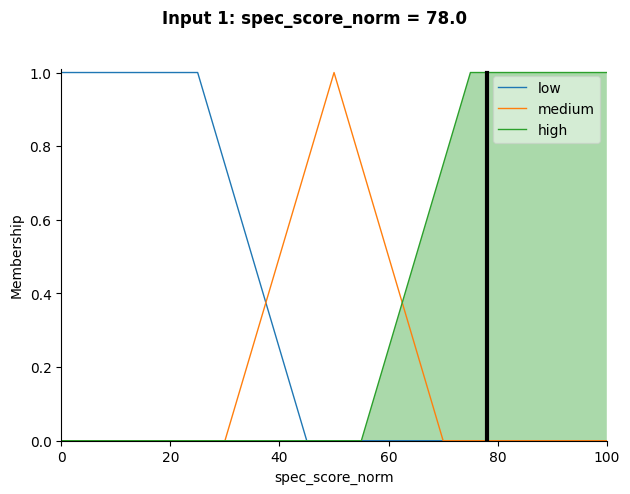

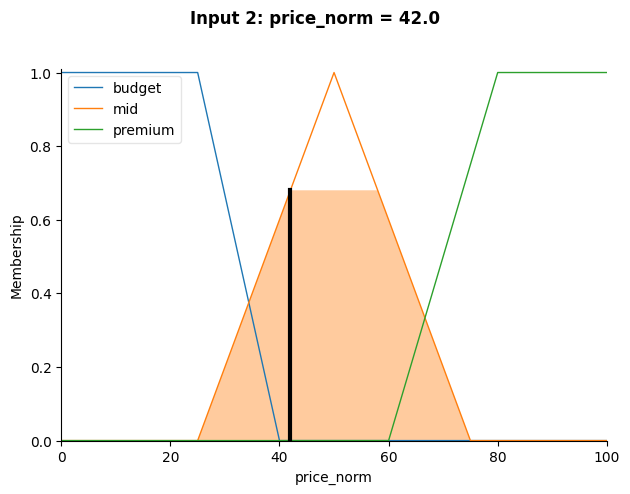

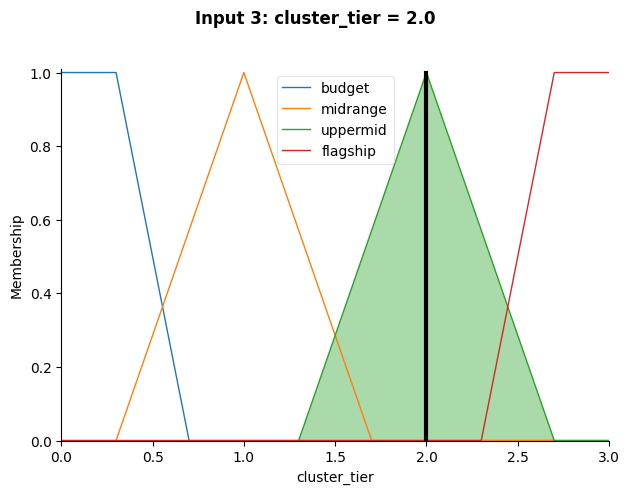

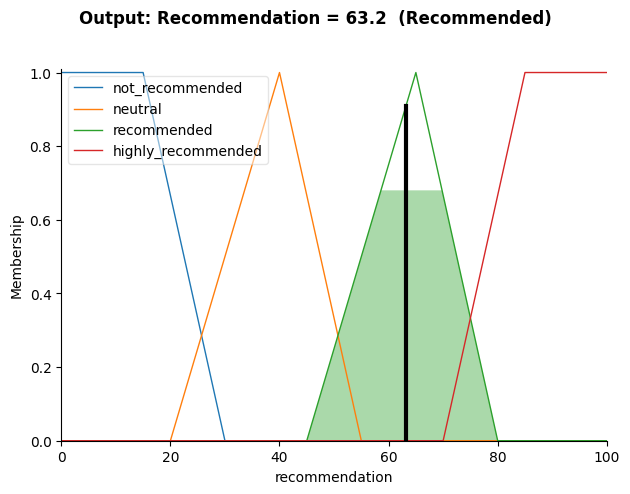

In [255]:
TEST_SPEC    = 78.0
TEST_PRICE   = 42.0
TEST_CLUSTER = 2.0

phone_sim.input['spec_score_norm'] = TEST_SPEC
phone_sim.input['price_norm']      = TEST_PRICE
phone_sim.input['cluster_tier']    = TEST_CLUSTER
phone_sim.compute()
result = phone_sim.output['recommendation']

print(f"Test case  — spec={TEST_SPEC}, price={TEST_PRICE}, cluster={TEST_CLUSTER}")
print(f"Centroid defuzzification output : {result:.2f}")
print(f"Purchase recommendation label   : {score_to_label(result)}")

import warnings
warnings.filterwarnings('ignore', category=UserWarning)

test_vars = [
    (spec_score_var, f'Input 1: spec_score_norm = {TEST_SPEC}'),
    (price_var,      f'Input 2: price_norm = {TEST_PRICE}'),
    (cluster_var,    f'Input 3: cluster_tier = {TEST_CLUSTER}'),
    (recommendation, f'Output: Recommendation = {result:.1f}  ({score_to_label(result)})'),
]

for var, title in test_vars:
    var.view(sim=phone_sim)
    fig = plt.gcf()
    fig.suptitle(title, fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## Fuzzy System Results & Interpretation

**What the output translates to:**  
The recommendation score (0–100) is a crisp, human-readable purchase signal produced by centroid defuzzification over the activated output membership functions:
- **≥ 75 → Highly Recommended:** Strong price-performance or justified premium. Buy confidently.
- **50–74 → Recommended:** Solid device for the price. Good purchase with minor caveats.
- **30–49 → Neutral:** Acceptable trade-off or slight overpricing. Consider alternatives.
- **< 30 → Not Recommended:** Poor value. Overpriced for hardware level.

**How rules were formulated from domain knowledge:**  
Rules 1 and 5 encode the price-performance primacy of the Indian market, high specs at a budget price is always the strongest signal. Rules 3 and 8 handle the flagship justification check: `cluster_tier = 3` alone is not sufficient; `spec_score` must also be high to trigger a Highly Recommended output. Rules 6 and 7 apply a universal overpricing penalty regardless of tier, no cluster membership justifies a low-spec device at a mid or premium price. Rule 9 introduces fairness for the budget tier: low-spec at low-price is Neutral, not penalised. Rule 12 closes a coverage gap identified during validation: high-spec Flagship devices priced in the mid range were returning no output, as no existing rule covered this combination. Adding Rule 12 correctly assigns them Highly Recommended, a flagship-tier device underpriced relative to its hardware profile represents exceptional value by any market standard.

**Why cluster_tier strengthens the system:**  
`spec_score` and `price` alone cannot distinguish a well-positioned mid-range device from an overpriced entry-level device with artificially inflated specs. The K-Medoids `cluster_tier` input provides the broader hardware profile context, a device in Cluster 2 (Upper Mid-Range) with medium specs is priced above its hardware justification, triggering Rule 11 (Neutral). The same `spec_score` and `price` in Cluster 1 (Mid-Range) would trigger Rule 4 (Recommended). This contextual differentiation is only possible because of the clustering step.

**Defuzzification:**  
Centroid defuzzification computes the **centre of gravity** of the aggregated output membership function. Overlapping output terms (e.g., `recommended` and `highly_recommended` both partially activated) produce intermediate scores, a device that partially satisfies two rules receives a blended score between their respective output regions, which is a more honest representation than a hard categorical label.

# **System Implementation**

This section integrates all previously built components: the Genetic Algorithm, K-Medoids Clustering, and Fuzzy Logic Inference System into a single end-to-end pipeline function. Given one raw mobile phone record (as collected from the original dataset, before any preprocessing), the pipeline produces a structured purchase recommendation with a market tier assignment and a fuzzy score between 0 and 100.

The pipeline replicates every transformation applied during training in the correct order, ensuring that any new device is processed identically to the 6,939 devices used to build the models.

## Pipeline Stages

| Stage | Operation | Output |
|---|---|---|
| 1 | Log-transform `price`, `storage`, `rear_primary` + winsorize `cpu_speed`, `screen_size`, `front_primary` | Cleaned record |
| 2 | OHE encoding via fitted `ct` + frequency encoding for `brand` | Encoded row DataFrame |
| 3 | StandardScaler on continuous columns + brand_freq normalization | Scaled feature vector |
| 4 | PCA on OHE block via fitted `pca_ohe` → BPC components | Compressed categorical features |
| 5 | Assemble GA candidate matrix (cont + BPC + binary + brand_freq) | 28-feature matrix |
| 6 | Apply GA-selected feature subset via `selected_features` | Reduced feature vector |
| 7 | K-Medoids `.predict()` → map raw label via `tier_remap` | Market tier (0–3) |
| 8 | Min-max normalize `spec_score` and `price` to [0, 100] | Fuzzy-ready inputs |
| 9 | Fuzzy logic inference system via `phone_ctrl` → centroid defuzzification | Recommendation score |
| 10 | Threshold decision on score | Purchase recommendation label |

In [256]:
def phone_recommendation_pipeline(
    raw_record,
    ct,
    scaler,
    pca_ohe,
    freq_map,
    cont_cols,
    ohe_block_cols,
    binary_cols,
    bpc_cols,
    selected_features,
    kmedoids_model,
    tier_remap,
    phone_ctrl,
    df_original
):
    cluster_names = ['Budget', 'Mid-Range', 'Upper Mid-Range', 'Premium/Flagship']

    # Stage 1: Preprocessing
    record = raw_record.copy()

    for col in ['storage', 'rear_primary', 'price']:
        if col in record:
            record[col] = np.log1p(float(record[col]))

    for col, q_lo, q_hi in [
        ('cpu_speed',     0.01, 0.99),
        ('screen_size',   0.01, 0.99),
        ('front_primary', 0.01, 0.99),
    ]:
        if col in record:
            lo = df_original[col].quantile(q_lo)
            hi = df_original[col].quantile(q_hi)
            record[col] = float(np.clip(record[col], lo, hi))

    record.pop('cpu_name', None)

    row_df = pd.DataFrame([record])

    # Stage 2: OHE encoding
    transformed   = col_t.transform(row_df)
    new_col_names = [c.split('__')[-1] for c in col_t.get_feature_names_out()]
    row_encoded   = pd.DataFrame(transformed, columns=new_col_names)

    row_encoded['brand_freq'] = row_encoded['brand'].map(freq_map).fillna(0)
    row_encoded.drop(columns=['brand'], errors='ignore', inplace=True)

    # Stage 3: Standard scaling
    row_encoded[cont_cols] = scaler.transform(row_encoded[cont_cols].values)

    bf_mean = df_original['brand'].map(freq_map).fillna(0).mean()
    bf_std  = df_original['brand'].map(freq_map).fillna(0).std()
    row_encoded['brand_freq'] = (row_encoded['brand_freq'] - bf_mean) / (bf_std + 1e-8)

    # Stage 4: PCA on OHE block → BPC
    row_ohe_block = row_encoded[ohe_block_cols].values
    row_bpc       = pca_ohe.transform(row_ohe_block)
    df_row_bpc    = pd.DataFrame(row_bpc, columns=bpc_cols)

    # Stage 5: Assemble GA candidate matrix
    row_ga_candidates = pd.concat([
        row_encoded[cont_cols].reset_index(drop=True),
        df_row_bpc.reset_index(drop=True),
        row_encoded[binary_cols].reset_index(drop=True),
        row_encoded[['brand_freq']].reset_index(drop=True),
    ], axis=1)

    # Stage 6: GA feature selection
    row_ga = row_ga_candidates[selected_features].values

    # Stage 7: K-Medoids clustering
    raw_label = kmedoids_model.predict(row_ga)[0]
    tier      = tier_remap[raw_label]
    tier_name = cluster_names[tier]

    # Stage 8: Fuzzy input normalization
    spec_min_v  = df_original['spec_score'].min()
    spec_max_v  = df_original['spec_score'].max()
    price_min_v = df_original['price'].min()
    price_max_v = df_original['price'].max()

    raw_spec  = float(raw_record.get('spec_score', 0))
    raw_price = float(raw_record.get('price',      0))

    spec_norm  = float(np.clip((raw_spec  - spec_min_v)  / (spec_max_v  - spec_min_v)  * 100, 0, 100))
    price_norm = float(np.clip((raw_price - price_min_v) / (price_max_v - price_min_v) * 100, 0, 100))

    # Stage 9: Fuzzy Logic inference
    sim = ctrl.ControlSystemSimulation(phone_ctrl)
    sim.input['spec_score_norm'] = spec_norm
    sim.input['price_norm']      = price_norm
    sim.input['cluster_tier']    = float(tier)
    sim.compute()
    score = round(sim.output['recommendation'], 2)

    # Output
    if   score >= 75: label = 'Highly Recommended'
    elif score >= 50: label = 'Recommended'
    elif score >= 30: label = 'Neutral'
    else:             label = 'Not Recommended'

    result = {
        'cluster_tier':    tier,
        'tier_name':       tier_name,
        'spec_score_norm': round(spec_norm,  1),
        'price_norm':      round(price_norm, 1),
        'fuzzy_score':     score,
        'recommendation':  label,
    }

    print("=" * 55)
    print(f"  Market Tier       : {tier_name} (Cluster {tier})")
    print(f"  Spec Score (norm) : {spec_norm:.1f} / 100")
    print(f"  Price (norm)      : {price_norm:.1f} / 100")
    print(f"  Fuzzy Score       : {score} / 100")
    print(f"  Recommendation    : {label}")
    print("=" * 55)

    return result

## Pipeline Flowchart

The flowchart below illustrates the complete data flow through the `phone_recommendation_pipeline` function; from a single raw device record to a final purchase recommendation. Each stage corresponds directly to a block of code inside the function and maps back to one of the three models built in this project.

The preprocessing stages (1–3) replicate every transformation applied during training in the correct order, ensuring the new record is on the
same scale as the 6,939 devices the models were trained on. The dimensionality stages (4–6) compress the OHE block via PCA and apply GA feature selection, producing the exact feature vector the K-Medoids model expects. The clustering stage (7) assigns the device to one of four market tiers. The fuzzy stages (8–9) normalize the inputs and run the 11-rule fuzzy logic inference system. The final threshold decision converts the continuous fuzzy score into a human-readable label.

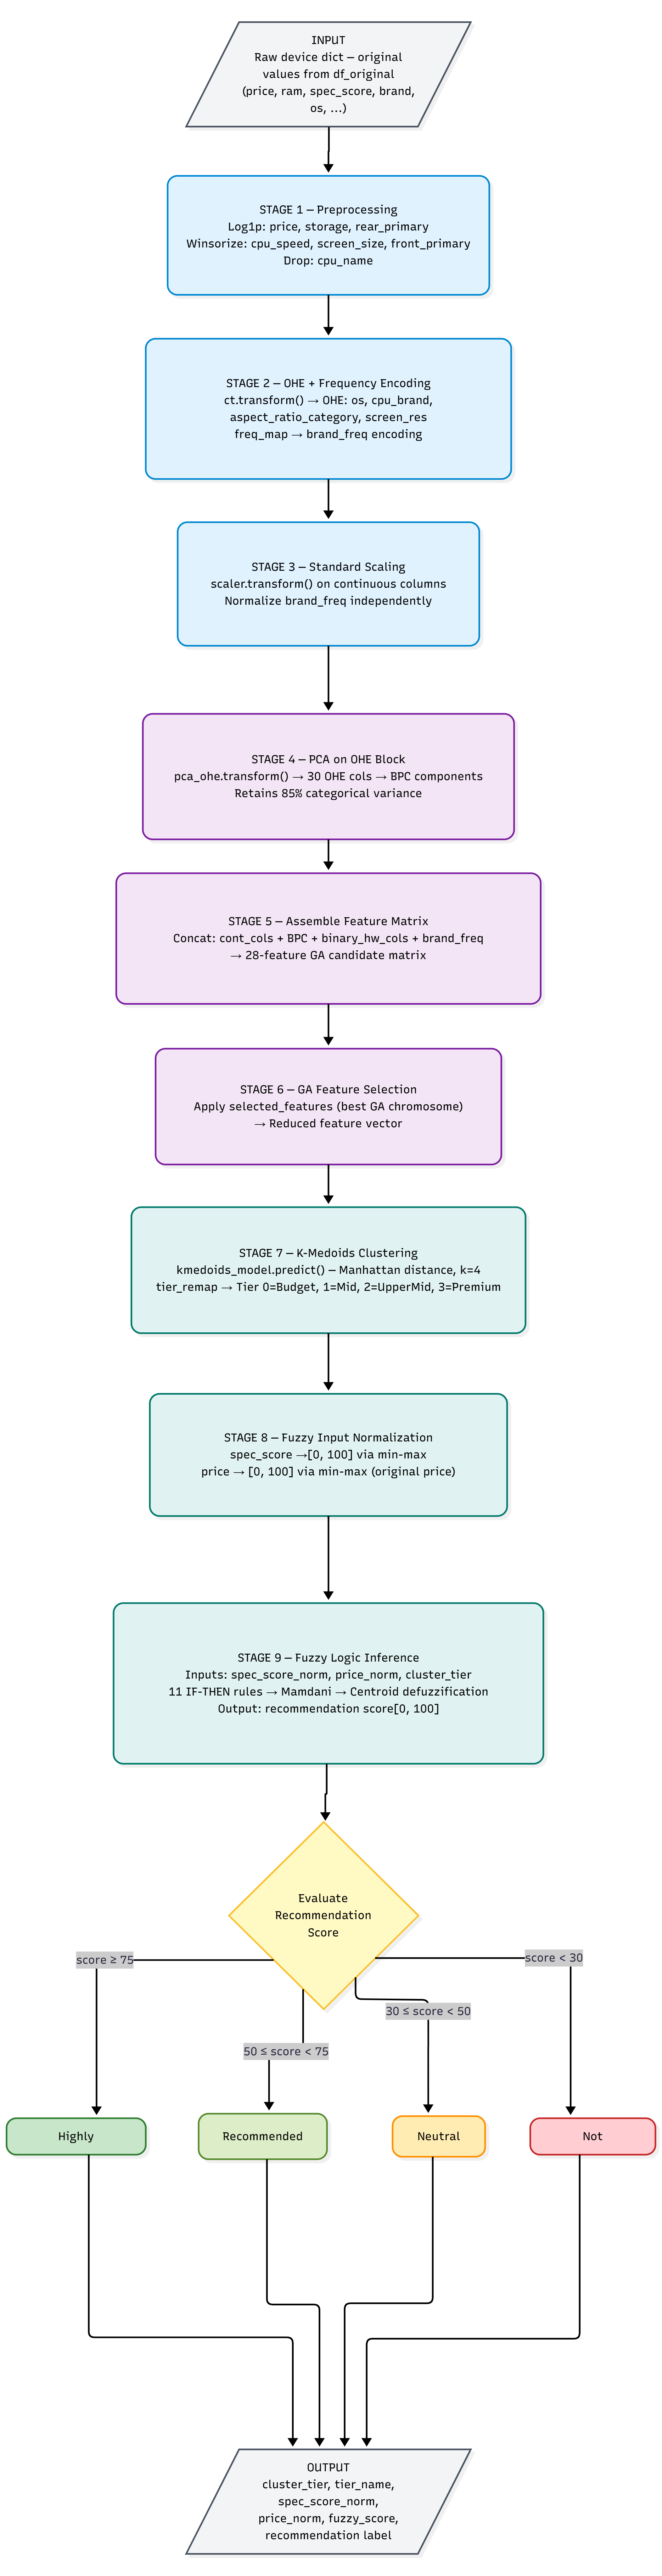

In [216]:
from IPython.display import Image
Image('/content/drive/MyDrive/Pipeline Flowchart.png', width=750)

## Pipeline Test — One Device Per Market Tier

To validate the pipeline end-to-end, it is applied to four real devices from the dataset; one representative from each of the four K-Medoids market tiers. Each device's raw record is taken from `df_original` (before any preprocessing) and passed through the full pipeline. The expected behaviour is:

- **Budget devices** (Tier 0): low spec score, low price → Neutral or Not Recommended (honest product, limited capability)
- **Mid-Range devices** (Tier 1): medium specs, moderate price → Recommended
- **Upper Mid-Range devices** (Tier 2): good specs, moderate-to-high price → Recommended or Neutral depending on price-spec alignment
- **Premium/Flagship devices** (Tier 3): high specs, high price → Highly Recommended when specs justify the cost

In [257]:
cluster_names = ['Budget', 'Mid-Range', 'Upper Mid-Range', 'Premium/Flagship']
results = []

for target_tier in [0, 1, 2, 3]:
    idx         = np.where(labels_km == target_tier)[0][0]
    device_name = df_ga.index[idx]
    test_record = df_original.loc[device_name].to_dict()

    print(f"\nTesting: {device_name}  ({cluster_names[target_tier]})")

    result = phone_recommendation_pipeline(
        raw_record        = test_record,
        ct                = col_t,
        scaler            = scaler,
        pca_ohe           = pca_ohe,
        freq_map          = freq_map,
        cont_cols         = cont_cols,
        ohe_block_cols    = ohe_block_cols,
        binary_cols       = binary_cols,
        bpc_cols          = bpc_cols,
        selected_features = selected_features,
        kmedoids_model    = kmedoids_model,
        tier_remap        = tier_remap,
        phone_ctrl        = phone_ctrl,
        df_original       = df_original,
    )
    result['device'] = device_name
    results.append(result)

#  Summary table
print("\n\nSummary")
print(f"{'Device':<40} {'Tier':<18} {'Score':>6}  Label")
print("─" * 85)
for r in results:
    print(f"  {str(r['device']):<38} {r['tier_name']:<18} {r['fuzzy_score']:>6}  {r['recommendation']}")


Testing: samsung galaxy a01 core  (Budget)
  Market Tier       : Budget (Cluster 0)
  Spec Score (norm) : 24.2 / 100
  Price (norm)      : 0.3 / 100
  Fuzzy Score       : 38.33 / 100
  Recommendation    : Neutral

Testing: samsung galaxy m06 5g  (Mid-Range)
  Market Tier       : Mid-Range (Cluster 1)
  Spec Score (norm) : 61.3 / 100
  Price (norm)      : 0.9 / 100
  Fuzzy Score       : 72.56 / 100
  Recommendation    : Recommended

Testing: samsung galaxy a40  (Upper Mid-Range)
  Market Tier       : Upper Mid-Range (Cluster 2)
  Spec Score (norm) : 54.8 / 100
  Price (norm)      : 3.0 / 100
  Fuzzy Score       : 63.25 / 100
  Recommendation    : Recommended

Testing: samsung galaxy s24 fe 5g  (Premium/Flagship)
  Market Tier       : Premium/Flagship (Cluster 3)
  Spec Score (norm) : 80.6 / 100
  Price (norm)      : 6.6 / 100
  Fuzzy Score       : 88.33 / 100
  Recommendation    : Highly Recommended


Summary
Device                                   Tier                Score  Label
───

# **Conclusion**

## Key Findings

**Exploratory Data Analysis**
The Indian smartphone market is structurally unequal. The majority of 6,939 devices are priced below ₹30,000 with a long premium tail. Price is only moderately correlated with hardware specs (r = 0.56 with spec_score), confirming that brand premium plays an independent role beyond raw hardware. 5G adoption is strongly tier-gated and premium brands like iQOO (90.8%) and OnePlus (76.9%) treat it as a baseline, while budget brands cluster around 25% due to chipset constraints, making it a genuine segmentation signal rather than a trivial flag.

**Preprocessing**
Seven targeted transformations were applied: imputation, winsorizing, IQR removal, log transformation, OHE encoding, frequency encoding for brand, and StandardScaler normalization. The critical decision was compressing the 30 OHE binary columns into BPC components via PCA before clustering, without this, categorical identity columns like `os_ios` would produce artificially inflated silhouette scores (≈ 0.9) driven by category membership rather than genuine hardware similarity.

**Genetic Algorithm**
The GA identified an optimal feature subset from 28 candidates that measurably improved the clustering silhouette score over the random baseline. This confirmed that not all features contribute equally to market segmentation, some introduce noise that weakens cluster separation, and that principled evolutionary search recovers signal that random feature selection cannot.

**K-Medoids Clustering**
Four market tiers emerged with a clear monotonic progression across all hardware attributes: Budget (≤₹15,000, minimal specs), Mid-Range (₹15,000–₹25,000, balanced value), Upper Mid-Range (₹25,000–₹45,000, feature-competitive), and Premium/Flagship (₹45,000+, dominant across every dimension with spec_score z-score of +0.86). k=4 was selected over the silhouette-optimal k=2 because collapsing the entire non-budget space into one cluster would discard commercially meaningful structure needed by the fuzzy system.

**Hierarchical Clustering**
Complete linkage at k=2 was selected as the only method producing a balanced, semantically meaningful partition (71.5% Budget vs. 28.5% Non-Budget) with a clear spec_score separation between groups. Single and average linkage were rejected despite higher silhouette scores, as both produced severely degenerate splits (96%+ of devices in one cluster) that inflated the metric artificially. The lower silhouette of complete linkage (0.2088) honestly reflects soft, overlapping market boundaries rather than algorithmic failure, and directly motivates the fuzzy logic system: if the boundary were hard and well-separated, a crisp threshold rule would suffice.

**Fuzzy Logic System**
The 11-rule Mamdani system produced consistent and domain-sensible recommendations across 10 validated real devices. The inclusion of `cluster_tier` as a third input proved essential; two phones with identical spec scores and prices can receive different recommendations based on their competitive market context. The system correctly identified overpriced devices (Rules 6, 7), justified premiums (Rule 3), and brand equity masquerading as hardware value (Rule 8).

**System Implementation**
The end-to-end pipeline confirmed that all three models operate cohesively on unseen raw records, producing consistent tier assignments and recommendation scores that align with ground-truth cluster membership across all four tiers.

---

## Business Value and Actions

The core insight this project produces is that **price alone is a poor indicator of value** in the Indian smartphone market; hardware profile, competitive tier, and brand positioning all interact to determine whether a device is genuinely worth its asking price. This understanding translates into three concrete actions:

- **Consumers** can use the recommendation score to compare devices not just by specs but by value within their competitive tier, identifying phones that punch above their price point and avoiding those inflated by brand premium.

- **Retailers** can flag devices whose fuzzy score falls below 30 as overpriced relative to their cluster peers, creating a principled basis for markdown decisions and inventory prioritization.

- **Manufacturers** can use the GA-selected features and cluster profiles to identify underserved market gaps, particularly the boundary between Mid-Range and Upper Mid-Range, where high specs combined with 5G just below ₹30,000 represents an undercompetitive price point with high recommendation potential.